# **Analisis Sentimen Publik terhadap AI yang Menggantikan Pekerjaan Manusia**

**Mata Kuliah:** Data Mining

**Nama Anggota Kelompok:**

1.   Muhammad Rafa Enrico (Ketua)
2.   Roihan Saputra

**Kelas TI-3C**

**Program Studi:** D4 Teknologi Rekayasa Komputer, Politeknik Negeri Semarang

## Rumusan Masalah
1. Bagaimana sebaran sentimen publik (positif, negatif, netral) terhadap isu AI yang menggantikan pekerjaan manusia berdasarkan komentar YouTube?
2. Algoritma klasifikasi mana di antara Decision Tree, Naïve Bayes, Random Forest, dan Logistic Regression yang memberikan performa terbaik untuk diimplementasikan sebagai model otomatisasi deteksi sentimen publik?

## Tujuan
1. Mengetahui sebaran sentimen publik terhadap isu AI yang menggantikan pekerjaan manusia.
2. Menemukan model klasifikasi yang paling tangguh (robust) untuk mengotomatisasi proses pelabelan sentimen pada data komentar di masa depan.

# **1. Import Library**

In [110]:
!pip install youtube-comment-downloader langdetect lingua-language-detector transformers torch --quiet
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from langdetect import detect, detect_langs, DetectorFactory, LangDetectException
from lingua import Language, LanguageDetectorBuilder
from transformers import pipeline
import torch
import joblib
import re
import os
import unicodedata

# **2. Load Datasets and Data Understanding**

**Fitur yang Kami Ambil:**
1. `video_url`: URL dari 6 video YouTube yang menjadi sumber data.
2. `author`: nama akun penulis komentar.
3. `comment`: isi teks komentar.
4. `likes`: jumlah *like* pada komentar.
5. `time`: waktu komentar dibuat, relatif terhadap tanggal *web scraping* dilakukan.


In [111]:
df = pd.read_csv("/content/youtube_comments.csv")
jumlah_baris_awal = len(df)  # dipakai pada ringkasan akhir (2.15)
df

,video_url,author,comment,likes,time
0,https://www.youtube.com/watch?v=t2WmNcToB3I,@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,2 maanden geleden
1,https://www.youtube.com/watch?v=t2WmNcToB3I,@robidarmawan71198,Menurut saya jika semua pengusaha berpikiran s...,189,2 maanden geleden
2,https://www.youtube.com/watch?v=t2WmNcToB3I,@wooshstar,jujur ya sebagai seorang yang bekerja di bidan...,6,2 maanden geleden (bewerkt)
3,https://www.youtube.com/watch?v=t2WmNcToB3I,@kadaladal7,Gw sebagai illustrator susah bener dapet klien...,588,2 maanden geleden
4,https://www.youtube.com/watch?v=t2WmNcToB3I,@Bagas_betok,Niat untung -> efesiensi phk->produksi mening...,85,2 maanden geleden
...,...,...,...,...,...
4453,https://www.youtube.com/watch?v=0LOHWGQwKtM,@HMF-7s,There’s a real awakening that cannot be stoppe...,0,5 maanden geleden
4454,https://www.youtube.com/watch?v=0LOHWGQwKtM,@fr0z3nk0,I'm a software engineer with 20 years of exper...,0,5 maanden geleden (bewerkt)
4455,https://www.youtube.com/watch?v=0LOHWGQwKtM,@nalen5050,so many way to discard that... I'll just take ...,2,5 maanden geleden
4456,https://www.youtube.com/watch?v=0LOHWGQwKtM,@georgioszampoukis,@nalen5050 Are you a software engineer? Beca...,0,5 maanden geleden


**Hasil `info()`:**

Seluruh kolom hasil *web scraping* bertipe `object` (string/kategorikal), termasuk kolom `likes` yang seharusnya berupa angka. Jumlah baris data yang kami miliki adalah 4.458.

In [112]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4458 entries, 0 to 4457
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   video_url  4458 non-null   object
 1   author     4458 non-null   object
 2   comment    4458 non-null   object
 3   likes      4458 non-null   object
 4   time       4458 non-null   object
dtypes: object(5)
memory usage: 174.3+ KB


**Hasil dari Describe :**

1. count (Jumlah data) : Total baris data yang terisi (tidak kosong/null) pada kolom tersebut.
2. Unique (Keunikan / Variasi Data): Jumlah nilai yang benar-benar berbeda (tidak kembar) di dalam kolom tersebut.
3. Top (Nilai Paling Sering Muncul / Modus) : Data atau teks apa yang frekuensi kemunculannya paling tinggi di kolom itu.
4. Freq (Frequency / Frekuensi) :
Seberapa banyak si nilai top tadi muncul di dalam dataset.


Tabel ini menunjukkan karakteristik data teks kami. Count adalah total data yang kami miliki, Unique menunjukkan seberapa banyak variasi datanya, Top adalah isi data yang paling dominan atau sering muncul, dan Freq menunjukkan berapa kali nilai Top tersebut muncul di dalam dataset

In [113]:
df.describe().T

,count,unique,top,freq
video_url,4458,6,https://www.youtube.com/watch?v=7Pq-S557XQU,1500
author,4458,3320,@edward-broo,36
comment,4458,4406,Up,6
likes,4458,241,0,2400
time,4458,62,2 maanden geleden,933


# **2. Preprocessing Data**

Pada tahap preprocessing, kami menerapkan pendekatan yang sistematis dan terstruktur untuk memastikan kualitas data mentah sebelum masuk ke tahap analisis dan pemodelan. Setiap langkah pembersihan dilakukan dengan konsisten menggunakan pola 3 tahap (3-Step Framework):

1. Cek: Menghitung jumlah data yang bermasalah dan menampilkan contohnya.

2. Bersihkan: Menghapus baris atau memperbaiki teksnya.

3. Verifikasi: Memastikan masalah pada tahap tersebut sudah selesai.

**Daftar Langkah Pembersihan:**

1. Nilai kosong: Hapus baris yang memiliki nilai kosong.

2. Duplikat baris persis: Hapus baris yang identik di seluruh kolom dan sisakan satu.

3. Spam judi online: Hapus baris komentar yang terindikasi promosi judi online.

4. Karakter tak terlihat (zero-width space): Hapus karakter tersembunyi atau Unicode non-standar dari teks.

5. URL di dalam komentar: Hapus tautan atau link web di dalam isi komentar.

6. Mention (@username): Hapus pemanggilan akun lain di dalam teks komentar.

7. Baris baru dan spasi berlebih: Ganti karakter newline dan spasi ganda menjadi satu spasi.

8. Duplikat teks komentar: Hapus komentar dengan isi teks yang sama (tanpa membedakan huruf besar/kecil) dan sisakan satu.

9. Komentar kosong atau terlalu pendek: Hapus komentar kosong atau yang kurang dari 3 kata.

10. Komentar tanpa huruf atau angka: Hapus baris komentar yang hanya berisi simbol atau emotikon saja.

11. Format kolom likes: Ubah tipe data jumlah like dari teks menjadi angka.

12. Hapus kolom waktu: Hapus kolom time karena tidak relevan dengan tujuan penelitian.

13. Judul video: Ganti kolom video_url dengan kolom video_title (judul video) agar lebih mudah dibaca.

14. Hapus kolom penulis: Hapus kolom author karena tidak dipakai sebagai fitur dan untuk menjaga privasi.

15. Deteksi bahasa: Tambah kolom bahasa (ditulis dengan nama lengkap, misalnya Indonesia dan Inggris) dengan deteksi berlapis. Tidak ada komentar yang dihapus pada langkah ini.

16. Ringkasan dan verifikasi akhir: Lakukan audit akhir pada seluruh DataFrame dan tampilkan rincian baris yang dihapus.

17. Menyimpan hasil: Simpan data hasil pembersihan ke file `youtube_comments_clean.csv`.

## **2.1 Nilai Kosong (Null)**

**Intinya:** Nilai kosong (null) adalah kolom yang tidak berisi data apa pun, seperti sel kosong di Excel. Baris seperti ini tidak dapat dipakai model sehingga dibuang.

**Contoh:** komentar yang kolom `comment`-nya kosong tidak memuat opini, sehingga barisnya dihapus. (Pada data kami tidak ditemukan nilai kosong.)

**Mengapa nilai kosong (null) harus ditangani?**

1. **Menyebabkan error saat pelatihan model:** Sebagian besar algoritma *machine learning*, termasuk Decision Tree, Naïve Bayes, Random Forest, dan Logistic Regression yang kami gunakan, bekerja dengan operasi numerik seperti perkalian matriks dan perhitungan jarak vektor. Algoritma tersebut tidak dapat mengolah nilai kosong (NaN/null), sehingga proses pelatihan akan menghasilkan error.

2. **Tidak mengandung informasi:** Dalam analisis sentimen, komentar yang bernilai null tidak memuat opini apa pun sehingga tidak ada pola yang dapat dipelajari oleh model.

3. **Mengganggu ekstraksi fitur:** Pada tahap ekstraksi fitur menggunakan TF-IDF, baris tanpa teks dapat membuat matriks representasi kata menjadi tidak konsisten.

In [114]:
null_counts = df.isnull().sum()
df_null = pd.DataFrame({
    "Nama Kolom": null_counts.index,
    "jumlah null": null_counts.values})
display(df_null)

total_null = null_counts.sum()
if total_null == 0:
  print("Tidak ditemukan nilai null pada dataset.")
else:
  print(f"Ditemukan {total_null} nilai null pada dataset.")
  print("\nContoh baris yang mengandung nilai null (sebelum dihapus):")
  display(df[df.isnull().any(axis=1)].head(5))

,Nama Kolom,jumlah null
0,video_url,0
1,author,0
2,comment,0
3,likes,0
4,time,0


Tidak ditemukan nilai null pada dataset.


**Hasil pengecekan:**

Tidak ditemukan nilai null pada kelima kolom (`video_url`, `author`, `comment`, `likes`, dan `time`), sehingga tidak ada baris yang perlu dihapus. Sel pembersihan di bawah tetap dijalankan sebagai pengaman agar alur preprocessing konsisten.

In [115]:
# 1. Hapus baris yang mengandung nilai null
jumlah_sebelum = len(df)
df = df.dropna().reset_index(drop=True)

# 2. Verifikasi
print(f"✅ Berhasil menghapus {jumlah_sebelum - len(df)} baris yang mengandung null.")
print(f"Sisa nilai null: {df.isnull().sum().sum()}")
print(f"📊 Jumlah baris dataset sekarang: {len(df)}")

✅ Berhasil menghapus 0 baris yang mengandung null.
Sisa nilai null: 0
📊 Jumlah baris dataset sekarang: 4458


## **2.2 Data Duplikat**

**Intinya:** Baris duplikat adalah baris yang isinya sama persis di semua kolom (video, penulis, komentar, jumlah *like*, dan waktu), sehingga hanya salinan. Satu baris disimpan dan salinannya dihapus.

**Contoh:** baris yang muncul dua kali dengan isi yang persis sama dihitung sebagai 1 baris saja.

**Mengapa data duplikat harus dihapus?**

1. **Mencegah kebocoran data (*data leakage*):** Saat data dibagi menjadi data latih dan data uji (misalnya 80:20), kalimat yang sama dapat masuk ke kedua bagian sekaligus. Akibatnya, model diuji menggunakan data yang sudah pernah dilihat saat pelatihan.

2. **Mencegah akurasi semu:** Kebocoran data tersebut dapat membuat akurasi model tampak sangat tinggi, padahal model hanya "menghafal" komentar duplikat, bukan memahami pola kalimat baru.

3. **Mencegah bias bobot kata:** Jika satu komentar (misalnya komentar spam atau bot) muncul berkali-kali, kata-kata di dalamnya akan dianggap terlalu penting dalam pembobotan TF-IDF sehingga model menjadi bias.

4. **Efisiensi komputasi:** Memproses teks yang sama berulang kali hanya menambah penggunaan memori dan waktu pelatihan tanpa menambah informasi baru.

In [116]:
dup_counts = df.duplicated().sum()
df_dup = pd.DataFrame({
    "Nama Kolom": ["duplicated"],
    "jumlah_dup": [dup_counts]
})

display(df_dup)

if dup_counts == 0:
  print("Tidak ditemukan baris duplikat.")
else:
  print(f"Ditemukan {dup_counts} baris duplikat.")
  print("\nContoh baris duplikat sebelum dihapus (baris asli dan salinannya ditampilkan berurutan):")
  display(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10))

,Nama Kolom,jumlah_dup
0,duplicated,11


Ditemukan 11 baris duplikat.

Contoh baris duplikat sebelum dihapus (baris asli dan salinannya ditampilkan berurutan):


,video_url,author,comment,likes,time
1750,https://www.youtube.com/watch?v=7Pq-S557XQU,@Pc275,It's here now Grey.... in a year from now an A...,0,3 jaar geleden
1751,https://www.youtube.com/watch?v=7Pq-S557XQU,@Pc275,It's here now Grey.... in a year from now an A...,0,3 jaar geleden
2213,https://www.youtube.com/watch?v=7Pq-S557XQU,@roberthollon7240,Agree,0,5 jaar geleden
2214,https://www.youtube.com/watch?v=7Pq-S557XQU,@roberthollon7240,Agree,0,5 jaar geleden
2215,https://www.youtube.com/watch?v=7Pq-S557XQU,@roberthollon7240,Agree,0,5 jaar geleden
880,https://www.youtube.com/watch?v=F8pz5wIO6gA,@k1kQ1-h5n,jawaban atas permasalahan ini simple. misalnya...,0,3 weken geleden
1397,https://www.youtube.com/watch?v=F8pz5wIO6gA,@k1kQ1-h5n,jawaban atas permasalahan ini simple. misalnya...,0,3 weken geleden
1429,https://www.youtube.com/watch?v=F8pz5wIO6gA,@k1kQ1-h5n,jawaban atas permasalahan ini simple. misalnya...,0,3 weken geleden
3468,https://www.youtube.com/watch?v=s1c4Ji6tNdw,@EdSurridge,AI gives increased productivity. That makes de...,0,7 maanden geleden
3915,https://www.youtube.com/watch?v=s1c4Ji6tNdw,@EdSurridge,AI gives increased productivity. That makes de...,0,7 maanden geleden


**Hasil pengecekan:**

Ditemukan **11 baris duplikat**, yaitu baris yang identik pada seluruh kolom (video, penulis, isi komentar, jumlah *like*, dan waktu). Tabel di atas menampilkan baris asli beserta salinannya secara berurutan. Baris pertama dari setiap kelompok dipertahankan, sedangkan salinannya dihapus.

In [117]:
total_duplikat = df.duplicated().sum()
print(f"Jumlah data duplikat ditemukan: {total_duplikat}")

df = df.drop_duplicates().reset_index(drop=True)

print(f"✅ Berhasil menghapus {total_duplikat} baris data duplikat.")
print(f"📊 Jumlah baris dataset sekarang: {len(df)}")

Jumlah data duplikat ditemukan: 11
✅ Berhasil menghapus 11 baris data duplikat.
📊 Jumlah baris dataset sekarang: 4447


## **2.3 Spam Judi Online**

**Intinya:** Spam judi online adalah iklan yang menyamar sebagai komentar biasa. Isinya tidak berkaitan dengan AI dan pekerjaan, sehingga dihapus.

**Contoh:** `7:18 𝘽𝙀𝙍𝙆𝘼𝙃99 kayak pelarian paling nyaman 🐯` tampak seperti ulasan biasa, tetapi nama situs judinya ditulis dengan huruf Unicode bergaya agar lolos dari filter. Baris seperti ini dihapus.

Komentar spam judi online dihapus dari dataset sesuai prinsip *Garbage In, Garbage Out*: data yang buruk akan menghasilkan prediksi yang buruk. Alasannya:

1. **Tidak relevan dengan topik:** Fokus penelitian ini adalah sentimen publik terhadap isu AI yang menggantikan pekerjaan manusia. Komentar promosi seperti "slot", "gacor", atau "maxwin" tidak mengandung opini terkait isu tersebut.

2. **Menurunkan performa model klasifikasi:** Model Decision Tree, Naïve Bayes, Random Forest, dan Logistic Regression mempelajari pola dari frekuensi kata (melalui TF-IDF). Jika spam dibiarkan, kosakata judi online dapat dianggap sebagai kata penting dan menurunkan akurasi saat memprediksi komentar asli.

3. **Menimbulkan bias pada kesimpulan:** Iklan judi online sering memakai kata-kata bernada ajakan atau euforia yang rentan terklasifikasi sebagai sentimen positif. Hal ini membuat persentase sentimen publik tidak mencerminkan opini yang sebenarnya.

Spam dideteksi dengan dua pola: (1) penggunaan huruf bergaya *fancy* dari blok Unicode *Mathematical Alphanumeric Symbols* (U+1D400–U+1D7FF) yang umum dipakai akun spam untuk menghindari filter, dan (2) nama situs "garuda hoki".

In [118]:
# 1. Pola regex spam judi online (flag (?i) diletakkan di awal pola agar pencocokan tidak membedakan huruf besar/kecil)
pola_spam = r"(?i)[\U0001D400-\U0001D7FF]|garuda\s*ho\s*ki"

# 2. Fungsi untuk mengecek komentar spam pada kolom comment
def cek_spam(data):
    return data["comment"].astype(str).str.contains(pola_spam, regex=True)

# 3. Hitung jumlah spam
total_spam = cek_spam(df).sum()
print(f"Komentar terindikasi spam judi online: {total_spam}")

# 4. Tampilkan 5 contoh komentar spam sebelum dihapus
print("\nContoh 5 komentar spam sebelum dihapus:")
display(df.loc[cek_spam(df), ["author", "comment"]].head(5).assign(comment=lambda d: d["comment"].str[:120]))

Komentar terindikasi spam judi online: 34

Contoh 5 komentar spam sebelum dihapus:


,author,comment
400,@KingMohammed-n1u,7:18 𝘽𝙀𝙍𝙆𝘼𝙃99 kayak pelarian paling nyaman 🐯
410,@KingInaya,11:02 Paling the best selalu jadi pilihan utam...
445,@ReedPascual-w9n,13:03 gue suka vibe-nya 𝘽𝙀𝙍𝙆𝘼𝙃99 📣
451,@Ortiz정우-f4b,8:31 Paling the best selalu pengen balik 𝘽𝙀𝙍𝙆𝘼...
454,@ScottIsak-g7z,5:39 𝘽𝙀𝙍𝙆𝘼𝙃99 tuh bikin nyaman parah.


**Hasil pengecekan:**

Ditemukan **34 komentar** yang terindikasi spam judi online. Pada contoh di atas, nama situs (𝘽𝙀𝙍𝙆𝘼𝙃99) ditulis dengan huruf Unicode bergaya agar lolos dari filter kata kunci biasa, dan diselipkan di dalam kalimat yang tampak seperti ulasan biasa dari akun yang berbeda-beda. Komentar ini tidak relevan dengan isu AI sehingga seluruh barisnya dihapus.

In [119]:
# 1. EKSEKUSI PENGHAPUSAN: ambil data yang BUKAN spam (~), lalu reset index
total_spam = cek_spam(df).sum()
df = df[~cek_spam(df)].reset_index(drop=True)

# 2. Verifikasi
print(f"✅ Berhasil menghapus {total_spam} komentar spam.")
print(f"Sisa komentar spam: {cek_spam(df).sum()}")
print(f"📊 Sisa baris dataset sekarang: {len(df)}")

✅ Berhasil menghapus 34 komentar spam.
Sisa komentar spam: 0
📊 Sisa baris dataset sekarang: 4413


## **2.4 Karakter Tak Terlihat (Zero-Width Space)**

**Intinya:** Karakter tak terlihat adalah karakter "hantu" yang tidak tampak di layar, tetapi dibaca komputer sebagai bagian dari teks. Karakter ini dibuang agar kata yang sama tidak dianggap berbeda.

**Contoh:** `'​\xa0@SepulangSekolah\xa0gas bang koi'` menjadi `'\xa0@SepulangSekolah\xa0gas bang koi'` (karakter `​` di awal dihapus). Sisa `\xa0` dirapikan pada langkah 2.6.

Sebagian komentar balasan diawali karakter tak terlihat seperti `\u200b` (zero-width space). Karakter ini tidak tampak di layar dan tidak dianggap spasi oleh Python, sehingga bisa lolos dari proses perapian spasi dan ikut terbaca sebagai bagian dari kata.

Pembersihan dilakukan langsung pada kolom `comment`, sehingga setelah tahap ini kolom tersebut sudah berisi teks yang bersih. Data mentah tetap tersimpan utuh pada file `youtube_comments.csv`.

Karakter yang dihapus: `\u200b` (zero-width space), `\u200c` (zero-width non-joiner), `\u2060` (word joiner), dan `\ufeff` (byte order mark).

Karakter tak terlihat perlu dihapus karena manusia dan mesin membaca teks dengan cara yang berbeda:

1. **Tokenisasi menjadi tidak konsisten:** Bagi manusia, kata "Pekerjaan" dan "Pe[zero-width]kerjaan" terlihat sama. Namun, bagi mesin (misalnya saat teks diubah menjadi angka dengan TF-IDF), keduanya dianggap sebagai dua kata yang berbeda.

2. **Frekuensi kata terpecah:** Algoritma seperti Naïve Bayes bergantung pada frekuensi kemunculan kata. Jika 100 komentar memuat kata "bagus", tetapi 30 di antaranya mengandung karakter tak terlihat, mesin hanya menghitung kata "bagus" sebanyak 70 kali sehingga bobot kata tersebut melemah.

3. **Menurunkan akurasi model:** Vocabulary menjadi membengkak oleh variasi kata yang sebenarnya sama, sehingga model klasifikasi (Decision Tree, Naïve Bayes, Random Forest, dan Logistic Regression) lebih sulit menemukan pola yang valid dan nilai akurasi, precision, serta recall dapat menurun.

In [120]:
# 1. Definisikan pola karakter tak terlihat
pola_tak_terlihat = r"[​‌⁠﻿]"

# 2. Fungsi pengecekan pada kolom comment
def cek_tak_terlihat(data):
    return data["comment"].astype(str).str.contains(pola_tak_terlihat, regex=True)

# 3. Hitung total komentar yang terdampak
print(f"Komentar yang mengandung karakter tak terlihat: {cek_tak_terlihat(df).sum()}")

# 4. Tampilkan 5 contoh komentar sebelum dibersihkan (repr menampilkan karakter tersembunyi)
print("\nContoh 5 komentar sebelum dibersihkan:")
contoh = df.loc[cek_tak_terlihat(df), ["author", "comment"]].head(5).copy()
contoh["comment (repr)"] = contoh["comment"].str[:80].apply(repr)
display(contoh[["author", "comment (repr)"]])

Komentar yang mengandung karakter tak terlihat: 273

Contoh 5 komentar sebelum dibersihkan:


,author,comment (repr)
21,@HashimotoSeiraVTuber,'\u200b\xa0@SepulangSekolah\xa0bahas juga soal...
22,@syathiralmakky8147,'\u200b\xa0@SepulangSekolah\xa0gas bang koi'
23,@lililiamm_,'\u200b\xa0@SepulangSekolah\xa0y'
26,@FahrezaMuhammad-d3j,'\u200b\xa0@albertcraftid2584\xa0 jokes SMP 😂😂...
40,@albertcraftid2584,'\u200b\xa0@FahrezaMuhammad-d3j\xa0nah tapi ja...


**Hasil pengecekan:**

Ditemukan **273 komentar** yang mengandung karakter tak terlihat. Pada contoh di atas, karakter `\u200b` (zero-width space) muncul di awal komentar balasan, tepat sebelum mention akun (misalnya `@SepulangSekolah`). Karakter ini tidak tampak pada tampilan biasa, tetapi terlihat pada tampilan `repr`. Karakter `\xa0` (non-breaking space) di sekitarnya tidak dihapus di tahap ini, melainkan dirapikan menjadi spasi biasa pada langkah 2.6.

In [121]:
# 1. Hapus karakter tak terlihat langsung pada kolom comment
df["comment"] = df["comment"].astype(str).str.replace(pola_tak_terlihat, "", regex=True)

# 2. Verifikasi
sisa_tak_terlihat = cek_tak_terlihat(df).sum()
print("✅ Karakter tak terlihat berhasil dibersihkan dari kolom comment!")
print(f"Sisa komentar yang masih mengandung karakter tak terlihat: {sisa_tak_terlihat}")

✅ Karakter tak terlihat berhasil dibersihkan dari kolom comment!
Sisa komentar yang masih mengandung karakter tak terlihat: 0


## **2.5 URL di Dalam Komentar**

**Intinya:** Tautan (URL) hanyalah alamat web dan tidak menyatakan pendapat. Hanya tautannya yang dihapus, sedangkan komentarnya tetap disimpan.

**Contoh (ilustrasi):** `Soal energi, ini sumbernya https://youtu.be/xxxx` menjadi `Soal energi, ini sumbernya`.

Tautan (misalnya `https://...` atau `www...`) tidak bermakna untuk analisis sentimen. Namun, tidak semua komentar ber-URL adalah spam. Sebagian berisi opini yang menyertakan tautan sebagai sumber. Karena itu, yang dihapus **hanya tautannya**, bukan seluruh komentarnya.

Berikut tiga alasan URL perlu dibersihkan:

1. **Tidak memiliki nilai sentimen:** URL hanyalah alamat halaman web dan tidak mengandung opini atau emosi terkait isu AI yang menggantikan pekerjaan manusia, sehingga tidak membantu model membedakan komentar positif, negatif, atau netral.

2. **Menjadi noise pada TF-IDF:** Pada model Decision Tree, Naïve Bayes, Random Forest, dan Logistic Regression yang belajar dari frekuensi kata, setiap URL yang berbeda akan dianggap sebagai kosakata baru. Hal ini membuat vocabulary membengkak tanpa manfaat dan dapat menurunkan akurasi prediksi.

3. **Membuang kuota token model Transformer:** Model pre-trained Transformer (XLM-RoBERTa) membaca teks dalam bentuk token dengan batas panjang tertentu. Satu URL dapat menghabiskan belasan hingga puluhan token untuk simbol seperti `http`, `://`, `www`, dan `.com`, sehingga opini di bagian akhir komentar berisiko terpotong.

In [122]:
# 1. Definisikan pola untuk mendeteksi URL (http, https, atau www)
pola_url = r"https?://\S+|www\.\S+"

# 2. Fungsi untuk mengecek URL pada comment (astype(str) agar aman dari error pada data kosong)
def cek_url(data):
    return data["comment"].astype(str).str.contains(pola_url, regex=True)

# 3. Tampilkan jumlah komentar yang ada URL-nya
print(f"Komentar yang mengandung URL: {cek_url(df).sum()}")

# 4. Tampilkan 5 contoh komentarnya di dalam tabel
print("\nContoh 5 komentar yang ada URL-nya (sebelum dibersihkan):")
df_contoh = pd.DataFrame({
    "Komentar": df.loc[cek_url(df), "comment"].head(5).str[:150].str.replace("\n", " ")
})
display(df_contoh)

Komentar yang mengandung URL: 11

Contoh 5 komentar yang ada URL-nya (sebelum dibersihkan):


,Komentar
712,https://youtube.com/shorts/pjT0ubmENWk?si=rUss...
836,https://youtu.be/difFzihUhPo?si=kogGg2E2cUw8EqbV
1607,"Soal constraint AI adalah energi, ini elon mus..."
1638,Bukan teori saya. Ini jensen huang sama elon m...
1648,I was thinking this video was getting out of d...


**Hasil pengecekan:**

Ditemukan **11 komentar** yang mengandung URL. Terdapat dua pola: komentar yang isinya hanya tautan (misalnya tautan video YouTube lain) dan komentar berisi opini yang menyertakan tautan sebagai sumber. Hanya teks tautannya yang dihapus. Komentar yang semula hanya berisi tautan akan menjadi kosong dan dibuang pada langkah 2.8.

In [123]:
# 1. Hapus URL dari comment (diganti spasi agar kata di sekitarnya tidak menyatu)
df["comment"] = df["comment"].str.replace(pola_url, " ", regex=True)

# 2. Verifikasi
sisa_url = cek_url(df).sum()
print("✅ Semua teks URL berhasil dibersihkan dari comment!")
print(f"📊 Sisa komentar yang masih mengandung URL: {sisa_url}")

✅ Semua teks URL berhasil dibersihkan dari comment!
📊 Sisa komentar yang masih mengandung URL: 0


## **2.6 Mention (@username), Baris Baru, dan Spasi Berlebih**

**Intinya:** Mention adalah nama akun yang dibalas (`@nama`). Nama akun bukan opini sehingga dihapus, lalu spasi dan baris baru dirapikan menjadi satu spasi biasa.

**Contoh:** `@SepulangSekolah gas bang koi` menjadi `gas bang koi`.

**Mention (`@username`)** memiliki sifat yang mirip dengan URL: berupa nama akun yang tidak mengandung opini, sehingga hanya menambah noise pada vocabulary.

**Baris baru (newline) dan spasi ganda** juga perlu dirapikan karena dua alasan:

1. **Mencegah kerusakan saat disimpan ke CSV:** Karakter baris baru (`\n`) di dalam komentar dapat membuat baris data terpecah saat dataset diekspor ke CSV atau Excel.

2. **Kerapian tokenisasi:** Teks dengan satu spasi antarkata memudahkan XLM-RoBERTa maupun TF-IDF memotong kata secara tepat.

In [124]:
# 1. Definisikan pola untuk mendeteksi mention (@username)
pola_mention = r"@\S+"

# 2. Fungsi untuk mengecek mention pada comment
def cek_mention(data):
    return data["comment"].astype(str).str.contains(pola_mention, regex=True)

# 3. Tampilkan jumlah komentar yang ada mention-nya
print(f"Komentar yang mengandung mention: {cek_mention(df).sum()}")

# 4. Tampilkan 5 contoh komentarnya di dalam tabel
print("\nContoh 5 komentar yang ada mention-nya (sebelum dibersihkan):")
df_contoh_mention = pd.DataFrame({
    "Komentar": df.loc[cek_mention(df), "comment"].head(5).str[:150].str.replace("\n", " ")
})
display(df_contoh_mention)

Komentar yang mengandung mention: 923

Contoh 5 komentar yang ada mention-nya (sebelum dibersihkan):


,Komentar
21,@SepulangSekolah bahas juga soal perusahaan A...
22,@SepulangSekolah gas bang koi
23,@SepulangSekolah y
26,@albertcraftid2584 jokes SMP 😂😂😂😂😂😂😂
40,@FahrezaMuhammad-d3j nah tapi jadi perseterua...


**Hasil pengecekan:**

Ditemukan **923 komentar** yang mengandung mention. Sebagian besar berupa balasan yang diawali nama akun yang dibalas (misalnya `@SepulangSekolah`). Nama akun tidak mengandung opini sehingga dihapus dari teks. Komentar yang semula hanya berisi mention akan menjadi kosong dan dibuang pada langkah 2.8.

In [125]:
# 1. Hapus mention (@username) dari comment (diganti spasi)
df["comment"] = df["comment"].str.replace(pola_mention, " ", regex=True)

# 2. Verifikasi
sisa_mention = cek_mention(df).sum()
print("✅ Semua mention (@username) berhasil dibersihkan dari comment!")
print(f"Sisa komentar yang masih mengandung mention: {sisa_mention}")

✅ Semua mention (@username) berhasil dibersihkan dari comment!
Sisa komentar yang masih mengandung mention: 0


**Perapian baris baru dan spasi berlebih**

Setelah URL dan mention dihapus, komentar dapat menyisakan spasi ganda, spasi di awal atau akhir teks, serta karakter baris baru. Seluruh jenis karakter spasi (spasi ganda, tab, newline, dan *non-breaking space*) diubah menjadi satu spasi biasa.

In [126]:
# 1. Fungsi perapian: ubah semua jenis karakter spasi menjadi satu spasi
def rapikan_spasi(teks):
    return " ".join(str(teks).split())

# 2. Hitung komentar yang belum rapi dan yang mengandung baris baru
belum_rapi = df["comment"] != df["comment"].apply(rapikan_spasi)
ada_newline = df["comment"].str.contains(r"[\r\n]", regex=True)
print(f"Komentar dengan spasi berlebih atau karakter spasi khusus: {belum_rapi.sum()}")
print(f"Komentar yang mengandung baris baru (newline): {ada_newline.sum()}")

# 3. Tampilkan 5 contoh sebelum dirapikan (repr menampilkan karakter tersembunyi)
print("\nContoh 5 komentar yang belum rapi (sebelum dirapikan):")
pendek = df["comment"].str.len() < 120   # pilih komentar pendek agar bagian yang bermasalah terlihat utuh
for teks in df.loc[belum_rapi & pendek, "comment"].head(5):
    print(repr(teks))

Komentar dengan spasi berlebih atau karakter spasi khusus: 1616
Komentar yang mengandung baris baru (newline): 636

Contoh 5 komentar yang belum rapi (sebelum dirapikan):
'\xa0 \xa0bahas juga soal perusahaan AI yang beli buku besar-besaran buat jadi bahan makanan AI terus bukunya dihancurin bang'
'\xa0 \xa0gas bang koi'
'\xa0 \xa0y'
'\xa0 \xa0 jokes SMP 😂😂😂😂😂😂😂'
'\xa0 \xa0nah tapi jadi perseteruan netizen maroko dengan spanyol akhir2 ini di threat'


**Hasil pengecekan:**

Ditemukan **1.616 komentar** dengan spasi berlebih atau karakter spasi khusus, dan **636 komentar** di antaranya mengandung baris baru (newline). Tampilan `repr` pada contoh memperlihatkan sisa `\xa0` (non-breaking space) dan spasi ganda yang tidak tampak pada tampilan biasa. Seluruhnya diubah menjadi satu spasi biasa.

In [127]:
# 1. Rapikan spasi pada comment
df["comment"] = df["comment"].apply(rapikan_spasi)

# 2. Verifikasi
sisa_belum_rapi = (df["comment"] != df["comment"].apply(rapikan_spasi)).sum()
sisa_newline = df["comment"].str.contains(r"[\r\n]", regex=True).sum()
print("✅ Spasi dan baris baru pada comment berhasil dirapikan!")
print(f"Sisa komentar yang belum rapi: {sisa_belum_rapi}")
print(f"Sisa komentar yang mengandung baris baru: {sisa_newline}")

✅ Spasi dan baris baru pada comment berhasil dirapikan!
Sisa komentar yang belum rapi: 0
Sisa komentar yang mengandung baris baru: 0


## **2.7 Duplikat Teks Komentar**

**Intinya:** Setelah dibersihkan, beberapa komentar bisa menjadi sama persis. Komentar dengan teks yang sama dihitung 1 saja, tanpa membedakan huruf besar dan kecil.

**Contoh:** `Up` dan `up` dianggap sama. Satu komentar disimpan, sisanya dihapus.

Pada tahap 2.2 yang dihapus adalah baris yang identik di seluruh kolom. Setelah URL dan mention dibersihkan, komentar yang semula berbeda dapat menjadi identik (misalnya "@akun1 setuju" dan "@akun2 setuju" menjadi "setuju"). Selain itu, terdapat komentar yang memang ditulis berulang oleh banyak akun, seperti "Up" atau komentar bot.

Komentar duplikat perlu dihapus karena alasan yang sama dengan tahap 2.2: mencegah kebocoran data antara data latih dan data uji, mencegah akurasi semu, serta mencegah bias bobot kata pada TF-IDF untuk model Decision Tree, Naïve Bayes, Random Forest, dan Logistic Regression.

Perbandingan dilakukan pada kolom `comment` **tanpa membedakan huruf besar dan kecil** (misalnya "Up" dan "up" dianggap sama), karena TF-IDF juga memperlakukan keduanya sebagai kata yang sama. Dari setiap kelompok duplikat, komentar pertama dipertahankan.

In [128]:
# 1. Kunci perbandingan: teks huruf kecil agar "Up" dan "up" dianggap sama
kunci = df["comment"].str.lower()

# 2. Hitung jumlah komentar duplikat
print(f"Komentar dengan teks duplikat: {kunci.duplicated().sum()}")

# 3. Tampilkan 5 teks yang paling sering berulang
print("\nTop 5 teks komentar yang paling sering berulang:")
top_dup = kunci.value_counts().head(5)
display(pd.DataFrame({"Komentar": top_dup.index.str[:80], "Jumlah muncul": top_dup.values}))

# 4. Tampilkan contoh baris duplikat sebelum dihapus (dikelompokkan berdasarkan teks)
print("\nContoh 10 baris duplikat sebelum dihapus (dikelompokkan berdasarkan teks):")
contoh_dup = (df.loc[kunci.duplicated(keep=False), ["author", "comment"]]
                .assign(kunci=kunci).sort_values("kunci").drop(columns="kunci").head(10))
display(contoh_dup)

Komentar dengan teks duplikat: 56

Top 5 teks komentar yang paling sering berulang:


,Komentar,Jumlah muncul
0,up,13
1,yes,8
2,lol,5
3,ketoprak 🤤🤤🤤,5
4,😂,4



Contoh 10 baris duplikat sebelum dihapus (dikelompokkan berdasarkan teks):


,author,comment
1870,@theplaguedoctor6271,-human brain
1915,@theplaguedoctor6271,-human Brain
2168,@gwalkingsylver,Agree
2174,@roberthollon7240,Agree
28,@Exalgg411,BANYAK ANAK BANYAK REZEQI
613,@Exalgg411,BANYAK ANAK BANYAK REZEQI
2414,@bstewart8891,Big brain time
2645,@bruhe8895,big brain time
1723,@Obi-Wan_Kenobi62,exactly
2060,@MuhammadAli-ey6gy,exactly


**Hasil pengecekan:**

Ditemukan **56 komentar** dengan teks duplikat (tanpa membedakan huruf besar/kecil). Teks yang paling sering berulang adalah komentar singkat seperti "up" (13 kali), "yes" (8 kali), dan "lol" (5 kali). Tabel contoh juga menunjukkan komentar yang sama persis dari akun berbeda (misalnya "Agree" dan "exactly"). Komentar pertama dari setiap kelompok dipertahankan dan sisanya dihapus.

In [129]:
# 1. Hapus duplikat (komentar pertama dipertahankan)
kunci = df["comment"].str.lower()
total_dup_teks = kunci.duplicated().sum()
df = df[~kunci.duplicated(keep="first")].reset_index(drop=True)

# 2. Verifikasi
sisa_dup_teks = df["comment"].str.lower().duplicated().sum()
print(f"✅ Berhasil menghapus {total_dup_teks} komentar duplikat.")
print(f"Sisa komentar duplikat: {sisa_dup_teks}")
print(f"📊 Jumlah baris dataset sekarang: {len(df)}")

✅ Berhasil menghapus 56 komentar duplikat.
Sisa komentar duplikat: 0
📊 Jumlah baris dataset sekarang: 4357


## **2.8 Komentar Kosong atau Terlalu Pendek**

**Intinya:** Komentar yang terlalu pendek tidak punya konteks untuk dinilai sentimennya. Komentar yang kurang dari 3 kata dihapus.

**Contoh:** `Up?`, `y`, `Ups`, dan `...` dihapus, sedangkan `gas bang koi` (3 kata) dipertahankan.

Komentar yang menjadi kosong setelah pembersihan (misalnya komentar yang hanya berisi URL atau mention) tidak memuat opini apa pun. Komentar yang terlalu pendek (misalnya "Up" atau "Mantap") juga sulit dinilai sentimennya karena tidak memiliki konteks, dan pelabelan zero-shot maupun deteksi bahasa menjadi kurang andal pada teks yang sangat singkat.

Batas minimal yang digunakan adalah **3 kata** (`MIN_KATA = 3`). Tabel pada sel pengecekan menunjukkan dampak berbagai batas minimal terhadap jumlah data, sehingga nilai ini dapat disesuaikan pada sel pembersihan jika diperlukan.

In [130]:
# 1. Hitung jumlah kata per komentar
jumlah_kata = df["comment"].str.split().str.len()

# 2. Dampak penghapusan pada berbagai batas minimal jumlah kata
batas = [1, 2, 3, 4, 5]
dampak = pd.DataFrame({
    "Batas minimal kata": batas,
    "Komentar yang terhapus": [(jumlah_kata < b).sum() for b in batas],
})
dampak["Persentase (%)"] = (dampak["Komentar yang terhapus"] / len(df) * 100).round(2)
display(dampak)

# 3. Tampilkan 10 contoh komentar yang kurang dari 3 kata
print("\nContoh 10 komentar yang kurang dari 3 kata (sebelum dihapus):")
display(df.loc[jumlah_kata < 3, ["comment"]].head(10))

,Batas minimal kata,Komentar yang terhapus,Persentase (%)
0,1,1,0.02
1,2,154,3.53
2,3,299,6.86
3,4,478,10.97
4,5,646,14.83



Contoh 10 komentar yang kurang dari 3 kata (sebelum dihapus):


,comment
20,Up?
23,y
24,Up
30,🫨
31,Ups
33,...
34,Up👍
35,Gassss
36,Gaasss
40,uppppp


**Hasil pengecekan:**

Tabel dampak menunjukkan bahwa semakin tinggi batas minimal kata, semakin banyak komentar yang terhapus: batas 1 kata (hanya komentar kosong) menghapus 1 komentar (0,02%), batas 2 kata menghapus 154 komentar (3,53%), batas 3 kata menghapus 299 komentar (6,86%), batas 4 kata menghapus 478 komentar (10,97%), dan batas 5 kata menghapus 646 komentar (14,83%). Contoh komentar yang kurang dari 3 kata ("Up?", "y", "Ups", "...", "Gassss") tidak memiliki konteks untuk dinilai sentimennya. Kami memilih batas **3 kata** karena hanya membuang sekitar 6,86% data yang hampir seluruhnya tidak bermakna, sedangkan batas yang lebih tinggi kemungkinan mulai membuang komentar singkat yang masih mengandung opini.

In [131]:
# 1. Tentukan batas minimal jumlah kata (ubah sesuai tabel pada sel pengecekan jika diperlukan)
MIN_KATA = 3

# 2. Hapus komentar kosong atau yang kurang dari MIN_KATA kata
jumlah_kata = df["comment"].str.split().str.len()
total_pendek = (jumlah_kata < MIN_KATA).sum()
df = df[jumlah_kata >= MIN_KATA].reset_index(drop=True)

# 3. Verifikasi
sisa_pendek = (df["comment"].str.split().str.len() < MIN_KATA).sum()
print(f"✅ Berhasil menghapus {total_pendek} komentar kosong atau kurang dari {MIN_KATA} kata.")
print(f"Sisa komentar yang terlalu pendek: {sisa_pendek}")
print(f"📊 Jumlah baris dataset sekarang: {len(df)}")

✅ Berhasil menghapus 299 komentar kosong atau kurang dari 3 kata.
Sisa komentar yang terlalu pendek: 0
📊 Jumlah baris dataset sekarang: 4058


## **2.9 Komentar Tanpa Huruf atau Angka**

**Intinya:** Komentar yang hanya berisi simbol atau emoji tidak punya kata yang bisa dianalisis, sehingga dihapus.

**Contoh:** `...` atau `😂 😂 😂` dihapus. Emoji yang menyertai teks, misalnya `jokes SMP 😂😂😂`, **tidak** dihapus dan tetap dipertahankan untuk analisis emoji pada tahap berikutnya.

Sebagian komentar hanya berisi simbol, tanda baca, atau emoji (misalnya "😂 😂 😂" atau "... ... ..."). Komentar seperti ini lolos dari batas jumlah kata pada tahap 2.8, tetapi tidak mengandung kata sehingga tidak memberi informasi bagi TF-IDF dan tidak dapat dianalisis secara tekstual.

Pengecekan memakai pola `[^\W_]` yang mengenali huruf dan angka dari semua alfabet. Komentar yang tidak memiliki satu pun karakter tersebut dihapus. Konsekuensinya, komentar yang hanya berisi emoji tidak ikut dianalisis.

In [132]:
# 1. Pola: komentar memiliki minimal satu huruf atau angka (mencakup huruf non-Latin)
pola_huruf_angka = r"[^\W_]"

# 2. Fungsi untuk mengecek komentar yang TIDAK memiliki huruf atau angka
def cek_tanpa_huruf_angka(data):
    return ~data["comment"].astype(str).str.contains(pola_huruf_angka, regex=True)

# 3. Tampilkan jumlah dan contohnya
print(f"Komentar tanpa huruf atau angka: {cek_tanpa_huruf_angka(df).sum()}")
print("\nContoh 5 komentar tanpa huruf atau angka (sebelum dihapus):")
display(df.loc[cek_tanpa_huruf_angka(df), ["comment"]].head(5))

Komentar tanpa huruf atau angka: 0

Contoh 5 komentar tanpa huruf atau angka (sebelum dihapus):


,comment


**Hasil pengecekan:**

Tidak ditemukan komentar yang hanya berisi simbol atau emoji (**0 komentar**). Komentar seperti itu sudah terbuang pada langkah 2.8 karena umumnya terdiri dari kurang dari 3 kata (misalnya "..." dan "🫨" pada contoh di langkah 2.8). Sel pembersihan tetap dijalankan sebagai pengaman.

In [133]:
# 1. Hapus komentar yang tidak memiliki huruf atau angka
total_tanpa_huruf = cek_tanpa_huruf_angka(df).sum()
df = df[~cek_tanpa_huruf_angka(df)].reset_index(drop=True)

# 2. Verifikasi
sisa_tanpa_huruf = cek_tanpa_huruf_angka(df).sum()
print(f"✅ Berhasil menghapus {total_tanpa_huruf} komentar tanpa huruf atau angka.")
print(f"Sisa komentar tanpa huruf atau angka: {sisa_tanpa_huruf}")
print(f"📊 Jumlah baris dataset sekarang: {len(df)}")

✅ Berhasil menghapus 0 komentar tanpa huruf atau angka.
Sisa komentar tanpa huruf atau angka: 0
📊 Jumlah baris dataset sekarang: 4058


## **2.10 Format Kolom Likes**

**Intinya:** Jumlah *like* dari YouTube dapat berupa teks singkatan seperti `1,2K`. Agar bisa dihitung, nilainya diubah menjadi angka biasa.

**Contoh:** `1,2K` menjadi 1200, `24K` menjadi 24000, dan `413` tetap 413.

Hasil `info()` menunjukkan bahwa kolom `likes` bertipe `object` (teks). Agar dapat dipakai untuk analisis statistik (rata-rata, variansi, standar deviasi, dan deteksi outlier) serta visualisasi, kolom ini harus diubah menjadi angka bulat.

Kolom `likes` dapat memuat format singkatan dari YouTube, misalnya "1,2K" (1.200) atau "1,5 mln" (1.500.000). Konversi dilakukan dengan aturan berikut:

1. Nilai kosong dianggap 0 *like*.
2. Akhiran `K` atau `rb` bernilai ribu, sedangkan `M`, `mln`, atau `jt` bernilai juta. Koma atau titik sebelum akhiran dibaca sebagai pecahan desimal.
3. Angka tanpa akhiran dengan titik atau koma dibaca sebagai pemisah ribuan (misalnya "1.234" menjadi 1234).
4. Nilai yang tidak dikenali ditandai kosong (`<NA>`) dan dilaporkan pada tahap verifikasi.

In [134]:
# 1. Cek tipe data kolom likes
print("Tipe data kolom likes:", df["likes"].dtype)

# 2. Cari nilai yang bukan angka murni (misalnya "1,2K")
bukan_angka = df.loc[~df["likes"].astype(str).str.fullmatch(r"\d+"), "likes"]
print(f"Nilai likes yang bukan angka murni: {len(bukan_angka)}")
print("Variasi nilai:", sorted(bukan_angka.astype(str).unique())[:20])

# 3. Tampilkan contoh baris sebelum dikonversi
print("\nContoh 5 baris dengan likes bukan angka murni (sebelum dikonversi):")
display(df.loc[bukan_angka.index, ["author", "likes", "comment"]].head(5)
          .assign(comment=lambda d: d["comment"].str[:60]))

# 4. Tampilkan 5 baris pertama kolom likes dalam bentuk teks (sebelum dikonversi)
print("\n5 baris pertama kolom likes (masih bertipe teks):")
display(df[["author", "likes"]].head(5))

Tipe data kolom likes: object
Nilai likes yang bukan angka murni: 42
Variasi nilai: ['1,1K', '1,2K', '1,3K', '1,4K', '1,5K', '1,7K', '1,8K', '11K', '13K', '14K', '19K', '1K', '2,2K', '2,6K', '24K', '26K', '2K', '3,3K', '3,4K', '3,5K']

Contoh 5 baris dengan likes bukan angka murni (sebelum dikonversi):


,author,likes,comment
1531,@CGPGrey,11K,I was thinking this video was getting out of d...
1532,@Yaxoi,"6,5K",You were right
1533,@maddy3852,13K,This wouldn't be scary if we lived in a world ...
1534,@Nameixist,30K,Aged like fine wine
1535,@andreasviken2949,"3,4K",This video has changed names more often than G...



5 baris pertama kolom likes (masih bertipe teks):


,author,likes
0,@aprie_rdw,413
1,@robidarmawan71198,189
2,@wooshstar,6
3,@kadaladal7,588
4,@Bagas_betok,85


**Hasil pengecekan:**

Seluruh nilai `likes` bertipe teks. Terdapat **42 nilai** yang bukan angka murni, yaitu singkatan ribuan dengan akhiran `K` (misalnya `1,1K`, `1,2K`, `11K`, dan `24K`), sedangkan nilai lainnya sudah berupa angka. Singkatan ini dikonversi menjadi angka bulat (misalnya `1,2K` menjadi 1.200) agar dapat dipakai untuk analisis statistik.

In [135]:
# 1. Fungsi konversi teks likes menjadi angka bulat
pengali = {"k": 1_000, "rb": 1_000, "m": 1_000_000, "mln": 1_000_000, "jt": 1_000_000}

def ubah_likes(nilai):
    teks = str(nilai).strip().lower().replace(" ", "").replace(" ", "")
    if teks in ("", "nan", "none"):
        return 0
    cocok = re.fullmatch(r"([\d.,]+)(k|rb|m|mln|jt)?", teks)
    if not cocok:
        return pd.NA
    angka, akhiran = cocok.groups()
    if akhiran:
        angka = angka.replace(",", ".")
        if angka.count(".") > 1:
            return pd.NA
        return int(round(float(angka) * pengali[akhiran]))
    return int(angka.replace(".", "").replace(",", ""))

# 2. Konversi kolom likes menjadi angka bulat
df["likes"] = df["likes"].apply(ubah_likes).astype("Int64")

# 3. Verifikasi
print("✅ Kolom likes berhasil diubah menjadi angka!")
print("Tipe data kolom likes sekarang:", df["likes"].dtype)
print(f"Nilai likes yang gagal dikonversi: {df['likes'].isna().sum()}")
display(df["likes"].describe())

✅ Kolom likes berhasil diubah menjadi angka!
Tipe data kolom likes sekarang: Int64
Nilai likes yang gagal dikonversi: 0


,likes
count,4058.0
mean,90.632578
std,1094.453585
min,0.0
25%,0.0
50%,0.0
75%,3.0
max,31000.0


In [136]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   video_url  4058 non-null   object
 1   author     4058 non-null   object
 2   comment    4058 non-null   object
 3   likes      4058 non-null   Int64 
 4   time       4058 non-null   object
dtypes: Int64(1), object(4)
memory usage: 162.6+ KB


## **2.11 Menghapus Kolom Waktu (`time`)**

**Intinya:** Kolom `time` berisi kapan komentar ditulis dalam bentuk teks relatif, misalnya `2 maanden geleden` (2 bulan yang lalu, dalam bahasa Belanda). Kolom ini tidak dipakai pada analisis sehingga dihapus.

Kolom `time` berisi teks waktu komentar dipublikasikan yang bersifat relatif terhadap tanggal *web scraping* (misalnya "2 maanden geleden"). Kolom ini kami hapus dengan alasan berikut:

1. **Tidak relevan dengan tujuan penelitian:** Penelitian ini memetakan sebaran sentimen dan membandingkan algoritma klasifikasi berdasarkan isi komentar. Waktu komentar dipublikasikan tidak dipakai sebagai fitur klasifikasi dan tidak dianalisis.

2. **Tidak dapat diubah menjadi tanggal yang pasti:** YouTube hanya menyediakan waktu relatif (dengan satuan berbahasa Belanda, seperti *maanden* dan *jaar*) dengan ketelitian sekitar per bulan, sehingga konversi hanya menghasilkan perkiraan tanggal yang kasar.

3. **Menyederhanakan dataset:** Kolom yang tidak dipakai dihapus agar dataset hasil preprocessing hanya berisi data yang dibutuhkan pada tahap berikutnya.

In [137]:
# 1. Tampilkan contoh nilai kolom time sebelum dihapus
print("Contoh 5 baris dengan kolom time (sebelum dihapus):")
display(df[["author", "comment", "time"]].head(5).assign(comment=lambda d: d["comment"].str[:60]))

# 2. Tampilkan jumlah nilai unik dan 5 nilai yang paling sering muncul
print(f"\nJumlah nilai unik pada kolom time: {df['time'].nunique()}")
print("\n5 nilai time yang paling sering muncul:")
display(df["time"].value_counts().head(5))

Contoh 5 baris dengan kolom time (sebelum dihapus):


,author,comment,time
0,@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol d...,2 maanden geleden
1,@robidarmawan71198,Menurut saya jika semua pengusaha berpikiran s...,2 maanden geleden
2,@wooshstar,jujur ya sebagai seorang yang bekerja di bidan...,2 maanden geleden (bewerkt)
3,@kadaladal7,Gw sebagai illustrator susah bener dapet klien...,2 maanden geleden
4,@Bagas_betok,Niat untung -> efesiensi phk->produksi meningk...,2 maanden geleden



Jumlah nilai unik pada kolom time: 61

5 nilai time yang paling sering muncul:


,count
time,
2 maanden geleden,829
7 maanden geleden,760
6 jaar geleden,327
5 jaar geleden,309
3 weken geleden,276


**Hasil pengecekan:**

Kolom `time` memiliki 61 nilai berbeda. Yang paling sering muncul adalah `2 maanden geleden` (829 komentar), `7 maanden geleden` (760), `6 jaar geleden` (327), `5 jaar geleden` (309), dan `3 weken geleden` (276).

**Arti kata Belanda pada kolom ini:** *maanden* = bulan, *jaar* = tahun, *weken* = minggu, *geleden* = yang lalu, dan *bewerkt* = sudah diedit. Teks berbahasa Belanda muncul kemungkinan karena pengaturan bahasa saat *web scraping*, bukan karena komentarnya berbahasa Belanda.

**Mengapa dihapus:** nilainya hanya perkiraan relatif. `2 maanden geleden` bisa berarti 2 bulan penuh sampai hampir 3 bulan, sehingga tidak bisa diubah menjadi tanggal yang pasti. Kolom ini juga tidak dipakai pada klasifikasi dan EDA, sehingga dihapus.

In [138]:
# 1. Hapus kolom time
df = df.drop(columns=["time"])

# 2. Verifikasi
print("✅ Kolom time berhasil dihapus!")
print("Kolom dataset sekarang:", list(df.columns))
print(f"📊 Jumlah baris: {len(df)}, jumlah kolom: {df.shape[1]}")

✅ Kolom time berhasil dihapus!
Kolom dataset sekarang: ['video_url', 'author', 'comment', 'likes']
📊 Jumlah baris: 4058, jumlah kolom: 4


## **2.12 Mengganti `video_url` dengan Judul Video (`video_title`)**

**Intinya:** Tautan video diganti dengan judul videonya agar tabel dan grafik mudah dibaca.

**Contoh:** `https://www.youtube.com/watch?v=7Pq-S557XQU` menjadi `Humans Need Not Apply - CGP Grey`.

Kolom `video_url` berisi tautan panjang yang sulit dibaca. Kolom ini kami ganti dengan kolom baru `video_title` yang berisi judul video, dengan alasan berikut:

1. **Lebih mudah dibaca:** Pada tabel dan grafik EDA serta pada presentasi, judul video langsung menjelaskan topik dan sumber komentar, sedangkan URL tidak.

2. **Informasi sumber tetap terjaga:** Setiap komentar tetap dapat dikelompokkan per video untuk membandingkan sentimen antarvideo.

3. **Tidak dipakai sebagai fitur:** URL tidak memuat informasi sentimen sehingga tidak diperlukan pada pemodelan.

Judul diberikan dengan mengambil ID video dari URL (bagian setelah `v=`), lalu memetakannya ke judul dari 6 video yang digunakan saat *web scraping*. Kolom `video_url` baru dihapus setelah judul berhasil dipetakan pada semua baris.

In [139]:
# 1. Ambil ID video dari URL
id_video = df["video_url"].str.extract(r"v=([\w-]+)")[0]

# 2. Cek jumlah video unik dan URL yang ID-nya gagal diambil
print(f"Jumlah video unik pada kolom video_url: {df['video_url'].nunique()}")
print(f"URL yang ID videonya gagal diambil: {id_video.isna().sum()}")

# 3. Tampilkan jumlah komentar per video_url sebelum diganti
print("\nJumlah komentar per video_url (sebelum diganti):")
per_url = df["video_url"].value_counts()
display(pd.DataFrame({"video_url": per_url.index, "Jumlah komentar": per_url.values}))

Jumlah video unik pada kolom video_url: 6
URL yang ID videonya gagal diambil: 0

Jumlah komentar per video_url (sebelum diganti):


,video_url,Jumlah komentar
0,https://www.youtube.com/watch?v=7Pq-S557XQU,1307
1,https://www.youtube.com/watch?v=s1c4Ji6tNdw,876
2,https://www.youtube.com/watch?v=F8pz5wIO6gA,810
3,https://www.youtube.com/watch?v=t2WmNcToB3I,721
4,https://www.youtube.com/watch?v=SDich6serU0,218
5,https://www.youtube.com/watch?v=0LOHWGQwKtM,126


**Hasil pengecekan:**

Kolom `video_url` berisi 6 URL unik sesuai dengan 6 video sumber, dan ID video dapat diambil dari setiap URL, sehingga semuanya dapat dipetakan ke judul videonya.

Jumlah komentar per video setelah pembersihan:

| Bahasa video | Judul video | Jumlah komentar |
|---|---|---|
| Inggris | Humans Need Not Apply - CGP Grey | 1.307 |
| Inggris | UK unemployment soars: is AI already taking our jobs? | 876 |
| Indonesia | Manusia Belum Tergantikan AI Karena Satu Hambatan Ini | 810 |
| Indonesia | Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI! | 721 |
| Inggris | The EXACT moment AI took my job... | 218 |
| Inggris | AI is taking their jobs. But they're fighting back. | 126 |

Jumlah komentar antarvideo tidak seimbang. Video CGP Grey memiliki puluhan ribu komentar, tetapi saat *web scraping* kami membatasi pengambilan sebanyak 1.500 komentar per video. Secara keseluruhan terdapat 1.531 komentar dari 2 video berbahasa Indonesia dan 2.527 komentar dari 4 video berbahasa Inggris. Ketimpangan ini perlu diperhatikan saat menafsirkan hasil perbandingan antarvideo.

In [140]:
# 1. Pemetaan ID video -> judul video (sesuai daftar video saat web scraping)
JUDUL_VIDEO = {
    "t2WmNcToB3I": "Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!",
    "F8pz5wIO6gA": "Manusia Belum Tergantikan AI Karena Satu Hambatan Ini",
    "7Pq-S557XQU": "Humans Need Not Apply - CGP Grey",
    "SDich6serU0": "The EXACT moment AI took my job...",
    "s1c4Ji6tNdw": "UK unemployment soars: is AI already taking our jobs?",
    "0LOHWGQwKtM": "AI is taking their jobs. But they're fighting back.",
}

# 2. Tambahkan kolom video_title berdasarkan ID video
df["video_title"] = id_video.map(JUDUL_VIDEO)

# 3. Hapus video_url hanya jika semua baris berhasil mendapat judul
tak_terpetakan = df["video_title"].isna().sum()
if tak_terpetakan == 0:
    df = df.drop(columns=["video_url"])
    # Letakkan video_title sebagai kolom pertama
    df = df[["video_title"] + [k for k in df.columns if k != "video_title"]]
    print("✅ Kolom video_title berhasil ditambahkan dan kolom video_url dihapus!")
else:
    print(f"⚠️ {tak_terpetakan} baris belum mendapat judul, sehingga video_url dipertahankan. Periksa kamus JUDUL_VIDEO.")

# 4. Verifikasi
print("Kolom dataset sekarang:", list(df.columns))
print("\nJumlah komentar per video:")
per_judul = df["video_title"].value_counts()
display(pd.DataFrame({"video_title": per_judul.index, "Jumlah komentar": per_judul.values}))

✅ Kolom video_title berhasil ditambahkan dan kolom video_url dihapus!
Kolom dataset sekarang: ['video_title', 'author', 'comment', 'likes']

Jumlah komentar per video:


,video_title,Jumlah komentar
0,Humans Need Not Apply - CGP Grey,1307
1,UK unemployment soars: is AI already taking ou...,876
2,Manusia Belum Tergantikan AI Karena Satu Hamba...,810
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,721
4,The EXACT moment AI took my job...,218
5,AI is taking their jobs. But they're fighting ...,126


## **2.13 Menghapus Kolom Penulis Komentar (`author`)**

**Intinya:** Kolom `author` berisi nama akun penulis komentar. Kolom ini tidak dipakai model dan memuat identitas pribadi, sehingga dihapus setelah dicek bahwa tidak ada akun yang mendominasi data.

Kolom `author` berisi nama akun penulis komentar. Kolom ini kami hapus dengan alasan berikut:

1. **Tidak dipakai sebagai fitur:** Sentimen ditentukan oleh isi komentar, bukan oleh siapa penulisnya. Nama akun juga tidak memiliki pola yang dapat dipelajari oleh model klasifikasi.

2. **Menjaga privasi:** Nama akun merupakan identitas pribadi. Kolom ini dihapus agar dataset hasil preprocessing yang disimpan dan dipresentasikan tidak memuat identitas penulis komentar.

3. **Sudah selesai dipakai:** Kolom `author` digunakan pada pembersihan sebelumnya (misalnya pengecekan duplikat baris persis pada langkah 2.2), sehingga dapat dihapus setelah semua langkah yang membutuhkannya selesai.

**Pengecekan sebelum dihapus:** kami memeriksa sebaran komentar per akun untuk memastikan tidak ada akun yang mendominasi data atau menulis komentar berulang (spam). Nama akun sengaja tidak ditampilkan pada hasil pengecekan untuk menjaga privasi.

In [141]:
# 1. Hitung jumlah komentar dan jumlah video untuk setiap akun
per_akun = df.groupby("author").agg(jumlah_komentar=("comment", "size"), jumlah_video=("video_title", "nunique"))

# 2. Ringkasan jumlah akun
print(f"Jumlah akun unik: {len(per_akun)} dari {len(df)} komentar")
print(f"Akun dengan 1 komentar: {(per_akun['jumlah_komentar'] == 1).sum()}")
banyak = per_akun[per_akun["jumlah_komentar"] > 1]
print(f"Akun dengan lebih dari 1 komentar: {len(banyak)}")
print(f"   - berkomentar hanya di 1 video: {(banyak['jumlah_video'] == 1).sum()}")
print(f"   - berkomentar di lebih dari 1 video: {(banyak['jumlah_video'] > 1).sum()}")

# 3. Sebaran jumlah komentar pada akun yang berkomentar lebih dari sekali
print("\nSebaran jumlah komentar per akun (hanya akun dengan lebih dari 1 komentar, 10 baris pertama):")
display(banyak["jumlah_komentar"].value_counts().sort_index().head(10)
        .rename_axis("Jumlah komentar per akun").reset_index(name="Jumlah akun"))

# 4. Akun dengan komentar terbanyak (nama akun tidak ditampilkan untuk menjaga privasi)
akun_teratas = per_akun["jumlah_komentar"].idxmax()
komentar_teratas = df[df["author"] == akun_teratas]
print(f"\nKomentar terbanyak dari satu akun: {len(komentar_teratas)} komentar "
      f"({len(komentar_teratas) / len(df) * 100:.2f}% dari seluruh komentar)")
print("Video tempat komentar tersebut ditulis:", komentar_teratas["video_title"].unique().tolist())
print("\nContoh 5 komentar dari akun tersebut:")
display(komentar_teratas[["comment"]].head(5).assign(comment=lambda d: d["comment"].str[:100]))

Jumlah akun unik: 3034 dari 4058 komentar
Akun dengan 1 komentar: 2518
Akun dengan lebih dari 1 komentar: 516
   - berkomentar hanya di 1 video: 511
   - berkomentar di lebih dari 1 video: 5

Sebaran jumlah komentar per akun (hanya akun dengan lebih dari 1 komentar, 10 baris pertama):


,Jumlah komentar per akun,Jumlah akun
0,2,329
1,3,100
2,4,27
3,5,19
4,6,9
5,7,10
6,8,7
7,9,5
8,10,4
9,11,1



Komentar terbanyak dari satu akun: 34 komentar (0.84% dari seluruh komentar)
Video tempat komentar tersebut ditulis: ['Manusia Belum Tergantikan AI Karena Satu Hambatan Ini']

Contoh 5 komentar dari akun tersebut:


,comment
827,emang fufufafa dah kebukti itu gibran ya?
920,"anjaiii.., anda klo debat real kalah kamu bang..."
921,"apa susahnya tinggal komen ""narasi ai yg menge..."
953,Tentu.. Tidak salah lagi ! tapi seru bang liha...
961,"sabar bangg, Netizen indo memang masih banyak ..."


**Hasil pengecekan:**

Dari 4.058 komentar terdapat 3.034 akun berbeda:

1. **2.518 akun** hanya menulis 1 komentar.
2. **516 akun** menulis lebih dari 1 komentar. Hampir semuanya (511 akun) hanya aktif di satu video, dan hanya 5 akun yang berkomentar di lebih dari satu video.
3. **Komentar terbanyak dari satu akun adalah 34 komentar** (sekitar 0,8% dari seluruh komentar), seluruhnya di satu video berbahasa Indonesia.

Isi komentar dari akun yang berkomentar banyak berbeda-beda dan saling menanggapi, misalnya membalas pendapat pengguna lain. Pola ini menunjukkan diskusi di kolom komentar, bukan spam, sehingga komentarnya tetap dipertahankan. Karena tidak ada akun yang mendominasi data, kolom `author` aman dihapus.

Catatan keterbatasan: setelah kolom `author` dihapus, kami tidak dapat memastikan komentar dari akun yang sama tidak masuk ke data latih dan data uji sekaligus pada tahap klasifikasi. Dampaknya kecil karena sebagian besar akun hanya menulis satu atau beberapa komentar.

In [142]:
# 1. Hapus kolom author
df = df.drop(columns=["author"])

# 2. Verifikasi
print("✅ Kolom author berhasil dihapus!")
print("Kolom dataset sekarang:", list(df.columns))
print(f"📊 Jumlah baris: {len(df)}, jumlah kolom: {df.shape[1]}")

✅ Kolom author berhasil dihapus!
Kolom dataset sekarang: ['video_title', 'comment', 'likes']
📊 Jumlah baris: 4058, jumlah kolom: 3


## **2.14 Deteksi Bahasa**

**Intinya:** Kolom baru `bahasa` menunjukkan bahasa setiap komentar, ditulis dengan **nama lengkap** (misalnya "Indonesia" dan "Inggris"), bukan singkatan seperti `id` atau `en`. Pada langkah ini **tidak ada komentar yang dihapus**.

**Mengapa bahasa perlu dideteksi?** Dataset berasal dari 6 video (2 berbahasa Indonesia dan 4 berbahasa Inggris). Video berbahasa Inggris ditonton oleh penonton dari banyak negara, sehingga komentarnya dapat berisi bahasa lain. Kolom `bahasa` dipakai pada EDA untuk melihat sebaran bahasa komentar pada setiap video.

**Mengapa tidak ada komentar yang dihapus?**

1. Model XLM-RoBERTa bersifat multibahasa, sehingga komentar dalam bahasa apa pun tetap dapat dilabeli sentimennya tanpa penyaringan bahasa.
2. Komentar berbahasa lain (misalnya Vietnam atau Spanyol) memang ada dan tetap merupakan data yang valid.
3. Kolom `bahasa` hanya informasi tambahan untuk analisis (EDA), bukan syarat penyaringan data.

**Mengapa tidak cukup memakai `langdetect`?** Library ini lemah pada komentar yang pendek, berbahasa gaul, ditulis dengan huruf kapital semua, atau memuat emoji. Misalnya, komentar "gas gas upload dong bang" terdeteksi sebagai bahasa Tagalog atau Jerman. Karena itu deteksi dilakukan secara **berlapis**. Teks dibersihkan dulu hanya untuk keperluan deteksi (huruf kecil, tanpa URL, mention, emoji, angka, dan tanda baca), sedangkan kolom `comment` termasuk emojinya tidak berubah. Setelah itu setiap komentar diperiksa berurutan, dan pemeriksaan berhenti pada lapisan pertama yang bisa memutuskan:

| Urutan | Pertanyaan | Jika ya, hasilnya | Contoh |
|---|---|---|---|
| 1 | Apakah komentar tidak memuat huruf sama sekali? | "Tidak terdeteksi" | `😂😂😂` |
| 2 | Apakah memuat kata khas Indonesia? (1 kata *kuat* seperti *banget*, *nggak*, *dong*, *wkwk*, atau 2 kata *umum* seperti *yang*, *untuk*, *aja*) | "Indonesia" | `gas gas upload dong bang` (karena ada kata *dong*) |
| 3 | Apakah terlalu pendek (kurang dari 10 huruf)? | "Tidak yakin" | `We need UBI` |
| 4 | Apakah `lingua` yakin pada salah satu dari 21 bahasa kandidat (keyakinan minimal 0,90)? | Nama bahasa hasil `lingua` | `Can't lose your job if you don't have one` (diharapkan "Inggris") |
| 5 | Jika belum yakin, tetapi kemungkinan besar Indonesia atau Inggris (minimal 50%): apakah hasilnya yakin ketika hanya Indonesia dan Inggris yang dibandingkan (minimal 0,80)? | "Indonesia" atau "Inggris" | `No this dumb debate` (diharapkan "Inggris") |
| 6 | Selain itu | "Tidak yakin" | komentar bercampur dua bahasa |

Alasan lapisan 2 memakai dua daftar kata: kata seperti *yang* juga muncul pada bahasa lain (misalnya nama "Andrew Yang"), sehingga kata seperti itu baru dianggap penanda bahasa Indonesia jika ada minimal dua kata umum dalam komentar yang sama. Lapisan 5 dibuat karena pada komentar pendek, `lingua` sering ragu di antara bahasa yang mirip (misalnya Inggris dengan Belanda atau Jerman), padahal kemungkinan besar komentar tersebut berbahasa Inggris.

**Istilah yang dipakai:**

1. **Keyakinan** adalah nilai 0 sampai 1 dari `lingua`. Nilai 0,90 berarti `lingua` 90% yakin pada bahasa tersebut.
2. **"Tidak yakin"** bukan berarti komentarnya salah atau dibuang. Komentar tetap dipakai, hanya bahasanya belum dapat dipastikan.
3. **Bahasa kandidat** pada `lingua` dibatasi pada 21 bahasa yang mungkin muncul pada komentar YouTube global. Bahasa Melayu tidak dimasukkan karena sangat mirip dengan bahasa Indonesia, sehingga komentar berbahasa Melayu akan masuk ke kategori Indonesia.

**Pengecekan:** sebagai pembanding, kami menjalankan `langdetect` saja pada seluruh komentar.

In [143]:
# 1. Atur seed agar hasil langdetect konsisten setiap kali dijalankan
DetectorFactory.seed = 0

# 2. Kamus kode bahasa langdetect -> nama lengkap bahasa
NAMA_BAHASA_LANGDETECT = {
    "af": "Afrikaans", "ar": "Arab", "bg": "Bulgaria", "bn": "Bengali", "ca": "Katalan",
    "cs": "Ceko", "cy": "Wales", "da": "Denmark", "de": "Jerman", "el": "Yunani",
    "en": "Inggris", "es": "Spanyol", "et": "Estonia", "fa": "Persia", "fi": "Finlandia",
    "fr": "Prancis", "gu": "Gujarati", "he": "Ibrani", "hi": "Hindi", "hr": "Kroasia",
    "hu": "Hungaria", "id": "Indonesia", "it": "Italia", "ja": "Jepang", "kn": "Kannada",
    "ko": "Korea", "lt": "Lituania", "lv": "Latvia", "mk": "Makedonia", "ml": "Malayalam",
    "mr": "Marathi", "ne": "Nepal", "nl": "Belanda", "no": "Norwegia", "pa": "Punjabi",
    "pl": "Polandia", "pt": "Portugis", "ro": "Rumania", "ru": "Rusia", "sk": "Slovakia",
    "sl": "Slovenia", "so": "Somalia", "sq": "Albania", "sv": "Swedia", "sw": "Swahili",
    "ta": "Tamil", "te": "Telugu", "th": "Thai", "tl": "Tagalog", "tr": "Turki",
    "uk": "Ukraina", "ur": "Urdu", "vi": "Vietnam", "zh-cn": "Mandarin (Sederhana)",
    "zh-tw": "Mandarin (Tradisional)",
}

# 3. Fungsi deteksi bahasa dasar (hanya langdetect), dipakai sebagai pembanding
def deteksi_langdetect(teks):
    try:
        kode = detect(teks)
    except LangDetectException:
        return "Tidak terdeteksi"
    return NAMA_BAHASA_LANGDETECT.get(kode, "Lainnya")

bahasa_langdetect = df["comment"].apply(deteksi_langdetect)

# 4. Distribusi bahasa hasil langdetect
distribusi = bahasa_langdetect.value_counts()
print("Distribusi bahasa hasil langdetect (sebelum diperbaiki):")
display(pd.DataFrame({
    "Bahasa": distribusi.index,
    "Jumlah komentar": distribusi.values,
    "Persentase (%)": (distribusi.values / len(df) * 100).round(2),
}))

# 5. Uji langdetect pada komentar pendek berbahasa Indonesia dan Inggris
contoh_uji = [
    "gas gas upload dong bang",
    "KALO SEMUA JADI ENGINEER AI SIAPA YANG MAU JADI TUKANG",
    "your link isn't working",
    "Have you met capitalism?",
    "Hahahahaha yea it's a little ironic",
]
print("\nHasil langdetect pada contoh komentar yang sebenarnya berbahasa Indonesia atau Inggris:")
display(pd.DataFrame({
    "comment": contoh_uji,
    "hasil langdetect": [deteksi_langdetect(t) for t in contoh_uji],
}))

# 6. Contoh komentar pendek (maksimal 5 kata) yang terdeteksi selain Indonesia/Inggris
pendek = df[(df["comment"].str.split().str.len() <= 5) & (~bahasa_langdetect.isin(["Indonesia", "Inggris"]))]
print(f"\nJumlah komentar pendek yang terdeteksi selain Indonesia/Inggris oleh langdetect: {len(pendek)}")
display(pd.DataFrame({
    "hasil langdetect": bahasa_langdetect[pendek.index],
    "comment": pendek["comment"].str[:80],
}).sample(min(10, len(pendek)), random_state=0))

Distribusi bahasa hasil langdetect (sebelum diperbaiki):


,Bahasa,Jumlah komentar,Persentase (%)
0,Inggris,2454,60.47
1,Indonesia,1398,34.45
2,Tagalog,36,0.89
3,Prancis,23,0.57
4,Swahili,16,0.39
5,Afrikaans,15,0.37
6,Jerman,15,0.37
7,Somalia,14,0.34
8,Belanda,12,0.30
9,Norwegia,12,0.30



Hasil langdetect pada contoh komentar yang sebenarnya berbahasa Indonesia atau Inggris:


,comment,hasil langdetect
0,gas gas upload dong bang,Tagalog
1,KALO SEMUA JADI ENGINEER AI SIAPA YANG MAU JAD...,Inggris
2,your link isn't working,Afrikaans
3,Have you met capitalism?,Prancis
4,Hahahahaha yea it's a little ironic,Tagalog



Jumlah komentar pendek yang terdeteksi selain Indonesia/Inggris oleh langdetect: 134


,hasil langdetect,comment
2494,Somalia,I wish you Good luck.
2051,Katalan,"it's a coronavirus, not influenza"
816,Swahili,wkwkwk fakta 🗿🗿
274,Slovenia,🤣🤣🤣🤣🤣kalo ini setuju
2577,Prancis,just enact prohobition
1421,Norwegia,SkyNet : 🙈
1879,Prancis,True... pretty true...
1534,Afrikaans,Aged like fine wine
1467,Swahili,Anjayyyy wkwkwkkw 😂😂😂
3102,Italia,cope cope cope


**Hasil pengecekan:**

Dari 4.058 komentar, `langdetect` menghasilkan **29 bahasa berbeda** (ditambah 1 komentar yang tidak terdeteksi), padahal video yang dipakai hanya berbahasa Indonesia dan Inggris:

1. **Inggris:** 2.454 komentar (60,47%).
2. **Indonesia:** 1.398 komentar (34,45%).
3. **Bahasa lain:** 206 komentar (5,08%), tersebar ke bahasa seperti Tagalog (36), Prancis (23), Swahili (16), Afrikaans (15), Jerman (15), dan Somalia (14).

Bahasa lain dalam jumlah sebanyak ini hampir pasti salah deteksi. Sebanyak **134 dari 206 komentar tersebut pendek** (maksimal 5 kata), misalnya `I wish you Good luck.` (terdeteksi Somalia), `Aged like fine wine` (Afrikaans), dan `wkwkwk fakta 🗿🗿` (Swahili).

Pengujian pada lima contoh komentar yang bahasanya sudah kami ketahui memperkuat hal ini:

| Komentar | Bahasa sebenarnya | Hasil `langdetect` |
|---|---|---|
| `gas gas upload dong bang` | Indonesia | Tagalog |
| `KALO SEMUA JADI ENGINEER AI SIAPA YANG MAU JAD...` | Indonesia | Inggris |
| `your link isn't working` | Inggris | Afrikaans |
| `Have you met capitalism?` | Inggris | Prancis |
| `Hahahahaha yea it's a little ironic` | Inggris | Tagalog |

Kelima contoh tersebut salah dideteksi. Jika hasil ini dipakai langsung, kolom `bahasa` akan menyesatkan dan analisis berikutnya ikut keliru. Karena itu dipakai deteksi berlapis seperti dijelaskan di atas.

In [144]:
# 1. Bahasa kandidat untuk lingua (kunci = nama bahasa pada lingua) -> nama lengkap bahasa
NAMA_BAHASA = {
    "INDONESIAN": "Indonesia", "ENGLISH": "Inggris", "SPANISH": "Spanyol", "FRENCH": "Prancis",
    "GERMAN": "Jerman", "PORTUGUESE": "Portugis", "ITALIAN": "Italia", "DUTCH": "Belanda",
    "RUSSIAN": "Rusia", "UKRAINIAN": "Ukraina", "POLISH": "Polandia", "TURKISH": "Turki",
    "VIETNAMESE": "Vietnam", "ARABIC": "Arab", "HINDI": "Hindi", "CHINESE": "Mandarin",
    "JAPANESE": "Jepang", "KOREAN": "Korea", "THAI": "Thai", "TAGALOG": "Tagalog",
    "SWEDISH": "Swedia",
}
BAHASA_ID = getattr(Language, "INDONESIAN")
BAHASA_EN = getattr(Language, "ENGLISH")

# Detektor 1: seluruh bahasa kandidat. Detektor 2: hanya Indonesia dan Inggris (untuk komentar pendek yang ragu)
detektor = LanguageDetectorBuilder.from_languages(*[getattr(Language, kunci) for kunci in NAMA_BAHASA]).build()
detektor_id_en = LanguageDetectorBuilder.from_languages(BAHASA_ID, BAHASA_EN).build()

# Mengubah objek bahasa lingua menjadi nama lengkap bahasa
def nama_lengkap(bahasa):
    for kunci, nama in NAMA_BAHASA.items():
        if bahasa == getattr(Language, kunci):
            return nama
    return "Lainnya"

# 2. Kata khas Indonesia
#    - KATA_KUAT: hampir pasti bahasa Indonesia, cukup 1 kata
#    - KATA_UMUM: umum di bahasa Indonesia tetapi bisa muncul di bahasa lain
#      (misalnya "yang" pada nama "Andrew Yang"), sehingga perlu minimal 2 kata
KATA_KUAT = {
    "saya", "aku", "gue", "gua", "gw", "loe", "gak", "gk", "nggak", "ngga", "enggak", "tidak", "tdk",
    "bukan", "udah", "sudah", "belum", "banget", "bgt", "dong", "deh", "sih", "nih", "tuh",
    "kocak", "mantap", "keren", "anjir", "anjay", "wkwk", "wkwkwk",
}
KATA_UMUM = {
    "yang", "yg", "untuk", "utk", "dengan", "dgn", "karena", "krn", "tapi", "tp", "juga", "jg",
    "lagi", "lg", "kamu", "kita", "kami", "mereka", "aja", "saja", "kok", "ini", "itu", "dari",
    "kalau", "klo", "kalo", "ada", "sama", "bisa", "apa",
}
POLA_TAWA = re.compile(r"(?:wk)+w?k?")  # wkwk, wkwkwk, wkwkw, dan sejenisnya

# 3. Batas keyakinan (ubah sesuai kebutuhan)
MIN_HURUF_DETEKSI = 10      # jumlah huruf minimal agar komentar dideteksi
MIN_KEYAKINAN = 0.90        # keyakinan minimal lingua (seluruh bahasa kandidat)
MIN_MASSA_ID_EN = 0.50      # jika minimal 50% keyakinan ada pada Indonesia/Inggris, komentar pendek diperiksa ulang
MIN_KEYAKINAN_ID_EN = 0.80  # keyakinan minimal saat hanya membandingkan Indonesia dan Inggris

# 4. Pembersihan khusus untuk deteksi (kolom comment tidak berubah)
def ambil_kata(teks):
    teks = re.sub(r"https?://\S+|www\.\S+|@\S+", " ", str(teks).lower())
    teks = teks.replace("’", "'")  # samakan tanda petik agar "don't" tetap satu kata
    # Pertahankan huruf (L), tanda gabung huruf (M), dan apostrof; emoji, angka, dan tanda baca menjadi spasi
    bersih = "".join(c if unicodedata.category(c)[0] in "LM" or c == "'" else " " for c in teks)
    kata = [k.strip("'") for k in bersih.split()]
    return [k for k in kata if any(unicodedata.category(c)[0] == "L" for c in k)]

# 5. Cek apakah komentar memuat kata khas Indonesia
def kata_khas_indonesia(kata):
    kuat = umum = 0
    for i, k in enumerate(kata):
        if k == "dong" and i > 0 and kata[i - 1] == "ding":  # "ding dong" adalah bahasa Inggris
            continue
        if k in KATA_KUAT or POLA_TAWA.fullmatch(k):
            kuat += 1
        elif k in KATA_UMUM:
            umum += 1
    return kuat >= 1 or umum >= 2

# 6. Deteksi berlapis: mengembalikan (nama bahasa, metode yang dipakai)
def tentukan_bahasa(teks):
    kata = ambil_kata(teks)
    if not kata:
        return "Tidak terdeteksi", "tanpa huruf"
    if kata_khas_indonesia(kata):
        return "Indonesia", "kata khas Indonesia"
    if len("".join(kata)) < MIN_HURUF_DETEKSI:
        return "Tidak yakin", "terlalu pendek"
    kalimat = " ".join(kata)
    hasil = detektor.compute_language_confidence_values(kalimat)
    if not hasil:
        return "Tidak yakin", "keyakinan rendah"
    if hasil[0].value >= MIN_KEYAKINAN:
        return nama_lengkap(hasil[0].language), "lingua"
    # Keyakinan belum cukup, tetapi jika kemungkinan besar Indonesia/Inggris: bandingkan hanya kedua bahasa itu
    massa_id_en = sum(h.value for h in hasil if h.language in (BAHASA_ID, BAHASA_EN))
    if massa_id_en >= MIN_MASSA_ID_EN:
        pilihan = detektor_id_en.compute_language_confidence_values(kalimat)[0]
        if pilihan.value >= MIN_KEYAKINAN_ID_EN:
            return nama_lengkap(pilihan.language), "lingua (Indonesia vs Inggris)"
    return "Tidak yakin", "keyakinan rendah"

# 7. Terapkan deteksi dan simpan pada kolom bahasa
baris_awal = len(df)
hasil = df["comment"].apply(tentukan_bahasa)
df["bahasa"] = hasil.str[0]
metode = hasil.str[1]

# 8. Verifikasi
print(f"✅ Kolom bahasa berhasil ditambahkan. Jumlah baris: {baris_awal} -> {len(df)} (tidak ada komentar yang dihapus).")

distribusi = df["bahasa"].value_counts()
print("\nDistribusi bahasa komentar (deteksi berlapis):")
display(pd.DataFrame({
    "Bahasa": distribusi.index,
    "Jumlah komentar": distribusi.values,
    "Persentase (%)": (distribusi.values / len(df) * 100).round(2),
}))

print("\nMetode yang menentukan bahasa:")
print(metode.value_counts())

berubah = (df["bahasa"] != bahasa_langdetect).sum()
print(f"\nKomentar yang hasilnya berbeda dari langdetect saja: {berubah} ({berubah / len(df) * 100:.2f}%)")

print("\nJumlah komentar per video berdasarkan bahasa:")
display(pd.crosstab(df["video_title"].str[:45].rename("judul video"), df["bahasa"]))

# 9. Contoh komentar berlabel "Tidak yakin" dan komentar berbahasa selain Indonesia/Inggris
tidak_yakin = df[df["bahasa"] == "Tidak yakin"]
print(f"\nContoh komentar berlabel 'Tidak yakin', dari total {len(tidak_yakin)} komentar:")
display(tidak_yakin[["comment"]].sample(min(10, len(tidak_yakin)), random_state=0)
        .assign(comment=lambda d: d["comment"].str[:80]))

lain = df[~df["bahasa"].isin(["Indonesia", "Inggris", "Tidak yakin", "Tidak terdeteksi"])]
print(f"\nContoh komentar berbahasa selain Indonesia/Inggris, dari total {len(lain)} komentar:")
display(lain[["bahasa", "comment"]].sample(min(10, len(lain)), random_state=0)
        .assign(comment=lambda d: d["comment"].str[:80]))

✅ Kolom bahasa berhasil ditambahkan. Jumlah baris: 4058 -> 4058 (tidak ada komentar yang dihapus).

Distribusi bahasa komentar (deteksi berlapis):


,Bahasa,Jumlah komentar,Persentase (%)
0,Inggris,2266,55.84
1,Indonesia,1432,35.29
2,Tidak yakin,356,8.77
3,Spanyol,2,0.05
4,Jerman,1,0.02
5,Vietnam,1,0.02



Metode yang menentukan bahasa:
comment
lingua                           1708
kata khas Indonesia              1108
lingua (Indonesia vs Inggris)     886
keyakinan rendah                  332
terlalu pendek                     24
Name: count, dtype: int64

Komentar yang hasilnya berbeda dari langdetect saja: 457 (11.26%)

Jumlah komentar per video berdasarkan bahasa:


bahasa,Indonesia,Inggris,Jerman,Spanyol,Tidak yakin,Vietnam
judul video,,,,,,
AI is taking their jobs. But they're fighting,0,124,0,0,2,0
Humans Need Not Apply - CGP Grey,0,1109,1,1,196,0
Manusia Belum Tergantikan AI Karena Satu Hamb,751,17,0,0,42,0
Pekerja Latih Robot Untuk Gantikan Mereka! KI,681,3,0,0,37,0
The EXACT moment AI took my job...,0,201,0,0,16,1
UK unemployment soars: is AI already taking o,0,812,0,1,63,0



Contoh komentar berlabel 'Tidak yakin', dari total 356 komentar:


,comment
162,apa si ?? SO ASIK !!
2096,The robot will kill you then.
3172,does if you win the 2.15 at York.
2509,Oouska Wizard What if... basic income?
1659,what kind of work?
2557,AlternateHistoryHub DESTROY ALL HUMANS
1854,"damn, what do work as?"
1231,LAWAN ULTRONN ya
782,tetep air bang
3121,So do CEOs



Contoh komentar berbahasa selain Indonesia/Inggris, dari total 4 komentar:


,bahasa,comment
2947,Vietnam,chừng nào các công cụ AI không minh bạch nguồn...
3687,Spanyol,Yo creo que nos enfrentaremos también a muchas...
2686,Jerman,durchgestrichen dein name ist einfach genial
1882,Spanyol,A propósito sua imagem de perfil esta errada. ...


**Hasil deteksi bahasa:**

Deteksi berlapis menghasilkan sebaran berikut dari 4.058 komentar (tidak ada komentar yang dihapus):

| Bahasa | Jumlah komentar | Persentase |
|---|---|---|
| Inggris | 2.266 | 55,84% |
| Indonesia | 1.432 | 35,29% |
| Tidak yakin | 356 | 8,77% |
| Spanyol | 2 | 0,05% |
| Jerman | 1 | 0,02% |
| Vietnam | 1 | 0,02% |

**Dibandingkan dengan `langdetect` saja:** komentar berlabel "Tidak yakin" turun, bahasa yang tidak masuk akal (seperti Tagalog, Swahili, dan Afrikaans) hilang, dan hanya 457 komentar (11,26%) yang labelnya berbeda dari hasil `langdetect`.

**Lapisan yang menentukan bahasa:**

| Metode | Jumlah komentar |
|---|---|
| `lingua` (keyakinan minimal 0,90) | 1.708 |
| Kata khas Indonesia | 1.108 |
| `lingua` (membandingkan hanya Indonesia dan Inggris) | 886 |
| Keyakinan rendah (menjadi "Tidak yakin") | 332 |
| Terlalu pendek, kurang dari 10 huruf (menjadi "Tidak yakin") | 24 |

Lapisan "membandingkan hanya Indonesia dan Inggris" menyelamatkan 886 komentar yang sebelumnya akan menjadi "Tidak yakin", terutama komentar pendek berbahasa Inggris.

**Sebaran bahasa per video:**

| Video | Bahasa dominan | Bahasa lain | Tidak yakin |
|---|---|---|---|
| Pekerja Latih Robot Untuk Gantikan Mereka! | Indonesia 681 | Inggris 3 | 37 |
| Manusia Belum Tergantikan AI Karena Satu Hambatan Ini | Indonesia 751 | Inggris 17 | 42 |
| Humans Need Not Apply - CGP Grey | Inggris 1.109 | Jerman 1, Spanyol 1 | 196 |
| UK unemployment soars: is AI already taking our jobs? | Inggris 812 | Spanyol 1 | 63 |
| The EXACT moment AI took my job... | Inggris 201 | Vietnam 1 | 16 |
| AI is taking their jobs. But they're fighting back. | Inggris 124 | - | 2 |

Video berbahasa Indonesia didominasi komentar berbahasa Indonesia, dan video berbahasa Inggris didominasi komentar berbahasa Inggris. Tidak ada komentar berlabel Indonesia di video berbahasa Inggris.

**Tentang komentar "Tidak yakin" (356 komentar, 8,77%):** sebagian besar adalah komentar pendek. Persentasenya sekitar 52% pada komentar 3 kata, sekitar 11% pada komentar 7 kata, dan hanya sekitar 1% pada komentar 12 kata atau lebih. Contohnya `YAY I hate AI`, `Poland as well`, dan `ini opening film Terminator ya?`. Komentar ini tetap dipertahankan dan tetap dapat dilabeli sentimennya oleh XLM-RoBERTa.

**Komentar berbahasa selain Indonesia dan Inggris (4 komentar):** satu berbahasa Vietnam, satu berbahasa Jerman, dan dua berlabel Spanyol (salah satunya sebenarnya berbahasa Portugis).

**Keterbatasan:** hasil deteksi tidak sempurna. Dari pemeriksaan manual, terdapat 20 komentar berlabel "Inggris" di video berbahasa Indonesia, dan hampir semuanya memang berbahasa Inggris. Hanya satu yang salah (komentar berbahasa Indonesia berlabel Inggris). Variasi tawa seperti `wkwkwkkw` dan kata yang huruf akhirnya dipanjangkan seperti `Anjayyyy` juga belum dikenali sehingga menjadi "Tidak yakin". Karena itu kolom `bahasa` hanya dipakai sebagai informasi tambahan untuk EDA dan tidak dipakai untuk menghapus komentar.

### **Perbandingan Jumlah Komentar yang Yakin dan Tidak Yakin**

Bagian ini membandingkan tiga metode deteksi bahasa dengan cara yang sederhana: **dari seluruh komentar, berapa yang yakin dan berapa yang tidak yakin**, tanpa menyebutkan bahasa apa yang terdeteksi.

1. **`langdetect`:** hasil `langdetect` saja.
2. **`lingua`:** hasil `lingua` saja (21 bahasa kandidat), tanpa daftar kata khas Indonesia dan tanpa lapis tambahan.
3. **`berlapis`:** deteksi berlapis yang dipakai pada kolom `bahasa`.

Agar adil, `langdetect` dan `lingua` menerima teks yang sama, yaitu teks yang sudah dibersihkan untuk deteksi (huruf kecil, tanpa emoji, URL, mention, angka, dan tanda baca).

**Cara penilaian:**

| Istilah | Artinya | Cara menilai |
|---|---|---|
| Terdeteksi | Komentar mendapat label bahasa | Komentar memuat minimal satu huruf dan metode memberi label bahasa. |
| Yakin | Metode cukup percaya pada hasilnya | `langdetect` dan `lingua`: komentar minimal 10 huruf **dan** keyakinan minimal 0,90. Berlapis: bahasa diputuskan oleh kata khas Indonesia atau `lingua`, yaitu label selain "Tidak yakin". |
| Tidak yakin | Terdeteksi, tetapi belum cukup percaya | Komentar kurang dari 10 huruf atau keyakinan di bawah 0,90. |

**Contoh membaca hasil:** jika ada 4.000 komentar, `lingua` yakin pada 3.000 komentar dan tidak yakin pada 1.000 komentar, sedangkan `langdetect` yakin pada 2.000 komentar dan tidak yakin pada 2.000 komentar, maka `lingua` lebih yakin pada 1.000 komentar lebih banyak daripada `langdetect`.

**Catatan:** "yakin" belum tentu benar. Karena itu, di bawah tabel utama ditampilkan juga jumlah komentar yang "yakin, tetapi bahasanya bukan Indonesia atau Inggris". Semua video berbahasa Indonesia atau Inggris, sehingga komentar seperti itu hampir pasti salah deteksi.

In [145]:
# 1. Fungsi pengukur: mengembalikan (label bahasa, keyakinan, jumlah huruf) dari teks yang sama
def ukur_langdetect(teks):
    kata = ambil_kata(teks)
    if not kata:
        return "Tidak terdeteksi", 0.0, 0
    try:
        teratas = detect_langs(" ".join(kata))[0]
    except LangDetectException:
        return "Tidak terdeteksi", 0.0, 0
    return NAMA_BAHASA_LANGDETECT.get(teratas.lang, "Lainnya"), teratas.prob, len("".join(kata))

def ukur_lingua(teks):
    kata = ambil_kata(teks)
    if not kata:
        return "Tidak terdeteksi", 0.0, 0
    hasil = detektor.compute_language_confidence_values(" ".join(kata))
    if not hasil:
        return "Tidak terdeteksi", 0.0, 0
    return nama_lengkap(hasil[0].language), hasil[0].value, len("".join(kata))

DetectorFactory.seed = 0
ukur_ld = pd.DataFrame(df["comment"].apply(ukur_langdetect).tolist(), columns=["label", "keyakinan", "huruf"], index=df.index)
ukur_li = pd.DataFrame(df["comment"].apply(ukur_lingua).tolist(), columns=["label", "keyakinan", "huruf"], index=df.index)

# 2. Status setiap komentar: Yakin, Tidak yakin, atau Tidak terdeteksi
def status_dari_ukur(u):
    yakin = (u["huruf"] >= MIN_HURUF_DETEKSI) & (u["keyakinan"] >= MIN_KEYAKINAN)
    return pd.Series(np.where(u["label"] == "Tidak terdeteksi", "Tidak terdeteksi",
                              np.where(yakin, "Yakin", "Tidak yakin")), index=u.index)

status_ld = status_dari_ukur(ukur_ld)
status_li = status_dari_ukur(ukur_li)
status_bl = pd.Series(np.where(df["bahasa"] == "Tidak terdeteksi", "Tidak terdeteksi",
                               np.where(df["bahasa"] == "Tidak yakin", "Tidak yakin", "Yakin")), index=df.index)

# 3. Ringkasan per metode
semua_label = {"langdetect": ukur_ld["label"], "lingua": ukur_li["label"], "berlapis": df["bahasa"]}
semua_status = {"langdetect": status_ld, "lingua": status_li, "berlapis": status_bl}
total = len(df)

tabel = pd.DataFrame({
    "Terdeteksi": {m: int((s_ != "Tidak terdeteksi").sum()) for m, s_ in semua_status.items()},
    "Yakin": {m: int((s_ == "Yakin").sum()) for m, s_ in semua_status.items()},
    "Tidak yakin": {m: int((s_ == "Tidak yakin").sum()) for m, s_ in semua_status.items()},
})
tabel["Yakin (%)"] = (tabel["Yakin"] / total * 100).round(2)
tabel["Tidak yakin (%)"] = (tabel["Tidak yakin"] / total * 100).round(2)
tabel.index.name = "Metode"

print(f"Jumlah seluruh komentar: {total}\n")
print("Perbandingan jumlah komentar yang yakin dan tidak yakin:")
display(tabel)

# 4. Catatan: komentar yang yakin tetapi bahasanya bukan Indonesia/Inggris (kemungkinan besar salah)
salah_yakin = pd.DataFrame({
    "Yakin tetapi bukan Indonesia/Inggris": {
        m: int(((semua_status[m] == "Yakin") & ~semua_label[m].isin(["Indonesia", "Inggris"])).sum())
        for m in semua_status
    }
})
salah_yakin.index.name = "Metode"
print("\nCatatan: komentar yang yakin, tetapi bahasanya bukan Indonesia atau Inggris (kemungkinan besar salah):")
display(salah_yakin)

Jumlah seluruh komentar: 4058

Perbandingan jumlah komentar yang yakin dan tidak yakin:


,Terdeteksi,Yakin,Tidak yakin,Yakin (%),Tidak yakin (%)
Metode,,,,,
langdetect,4058,3682,376,90.73,9.27
lingua,4058,2707,1351,66.71,33.29
berlapis,4058,3702,356,91.23,8.77



Catatan: komentar yang yakin, tetapi bahasanya bukan Indonesia atau Inggris (kemungkinan besar salah):


,Yakin tetapi bukan Indonesia/Inggris
Metode,
langdetect,86
lingua,5
berlapis,4


## **2.15 Ringkasan dan Verifikasi Akhir**

**Intinya:** Sebelum disimpan, seluruh dataset diperiksa sekali lagi dari awal untuk memastikan semua masalah yang dibersihkan pada langkah 2.1 sampai 2.14 benar-benar sudah hilang dan tidak ada masalah baru yang muncul. Ini seperti pemeriksaan terakhir sebelum barang dikemas.

**Contoh:** jika setelah seluruh pembersihan masih ada komentar yang mengandung URL, pemeriksaan ini akan menampilkan jumlahnya dan statusnya berubah menjadi "Perlu dicek".

Pemeriksaan yang dilakukan:

1. Nilai kosong, baris duplikat persis, dan teks komentar duplikat.
2. Sisa karakter tak terlihat, URL, mention, serta spasi atau baris baru berlebih pada komentar.
3. Komentar yang kurang dari 3 kata atau tidak memiliki huruf dan angka.
4. Nilai `likes` yang kosong atau negatif.
5. Kolom akhir sesuai rencana: `video_title`, `comment`, `likes`, dan `bahasa`.

Semua pemeriksaan harus menghasilkan jumlah masalah **0**. Setelah itu ditampilkan ringkasan jumlah baris sebelum dan sesudah preprocessing, distribusi bahasa, dan statistik jumlah *like*.

In [146]:
# 1. Struktur akhir dataset
print("Struktur dataset akhir:")
df.info()

# 2. Pemeriksaan kualitas data (semua harus bernilai 0)
komentar = df["comment"]
pemeriksaan = {
    "Nilai kosong (null) pada seluruh kolom": int(df.isna().sum().sum()),
    "Baris duplikat persis": int(df.duplicated().sum()),
    "Teks komentar duplikat (tanpa membedakan huruf besar/kecil)": int(komentar.str.lower().duplicated().sum()),
    "Komentar dengan karakter tak terlihat": int(komentar.str.contains(r"[​‌⁠﻿]", regex=True).sum()),
    "Komentar dengan URL": int(komentar.str.contains(r"https?://\S+|www\.\S+", regex=True).sum()),
    "Komentar dengan mention (@username)": int(komentar.str.contains(r"@\S+", regex=True).sum()),
    "Komentar dengan spasi ganda, spasi di tepi, atau baris baru": int((komentar != komentar.apply(lambda t: " ".join(t.split()))).sum()),
    "Komentar kurang dari 3 kata": int((komentar.str.split().str.len() < 3).sum()),
    "Komentar tanpa huruf atau angka": int((~komentar.str.contains(r"[^\W_]", regex=True)).sum()),
    "Nilai likes kosong atau negatif": int(df["likes"].isna().sum() + (df["likes"] < 0).sum()),
    "Kolom tidak sesuai rencana": int(list(df.columns) != ["video_title", "comment", "likes", "bahasa"]),
}
hasil_audit = pd.DataFrame({"Pemeriksaan": list(pemeriksaan), "Jumlah bermasalah": list(pemeriksaan.values())})
hasil_audit["Status"] = hasil_audit["Jumlah bermasalah"].apply(lambda n: "✅ Lolos" if n == 0 else "⚠️ Perlu dicek")
print("\nHasil pemeriksaan kualitas data:")
display(hasil_audit)

# 3. Ringkasan jumlah baris sebelum dan sesudah preprocessing
terhapus = jumlah_baris_awal - len(df)
print(f"\nJumlah baris: {jumlah_baris_awal} (awal) -> {len(df)} (akhir)")
print(f"Total baris yang dihapus: {terhapus} ({terhapus / jumlah_baris_awal * 100:.2f}%)")
print("Kolom akhir:", list(df.columns))

# 4. Distribusi bahasa dan statistik jumlah like
print("\nDistribusi bahasa:")
display(df["bahasa"].value_counts())
print("Statistik jumlah like:")
display(df["likes"].describe())

# 5. Contoh 5 baris acak dari dataset akhir
print("Contoh 5 baris acak dari dataset akhir:")
display(df.sample(5, random_state=0).assign(comment=lambda d: d["comment"].str[:80]))

Struktur dataset akhir:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   video_title  4058 non-null   object
 1   comment      4058 non-null   object
 2   likes        4058 non-null   Int64 
 3   bahasa       4058 non-null   object
dtypes: Int64(1), object(3)
memory usage: 130.9+ KB

Hasil pemeriksaan kualitas data:


,Pemeriksaan,Jumlah bermasalah,Status
0,Nilai kosong (null) pada seluruh kolom,0,✅ Lolos
1,Baris duplikat persis,0,✅ Lolos
2,Teks komentar duplikat (tanpa membedakan huruf...,0,✅ Lolos
3,Komentar dengan karakter tak terlihat,0,✅ Lolos
4,Komentar dengan URL,0,✅ Lolos
5,Komentar dengan mention (@username),0,✅ Lolos
6,"Komentar dengan spasi ganda, spasi di tepi, at...",0,✅ Lolos
7,Komentar kurang dari 3 kata,0,✅ Lolos
8,Komentar tanpa huruf atau angka,0,✅ Lolos
9,Nilai likes kosong atau negatif,0,✅ Lolos



Jumlah baris: 4458 (awal) -> 4058 (akhir)
Total baris yang dihapus: 400 (8.97%)
Kolom akhir: ['video_title', 'comment', 'likes', 'bahasa']

Distribusi bahasa:


,count
bahasa,
Inggris,2266
Indonesia,1432
Tidak yakin,356
Spanyol,2
Jerman,1
Vietnam,1


Statistik jumlah like:


,likes
count,4058.0
mean,90.632578
std,1094.453585
min,0.0
25%,0.0
50%,0.0
75%,3.0
max,31000.0


Contoh 5 baris acak dari dataset akhir:


,video_title,comment,likes,bahasa
914,Manusia Belum Tergantikan AI Karena Satu Hamba...,kamu sudah basa penuh komentar saya? lagian un...,0,Indonesia
3122,UK unemployment soars: is AI already taking ou...,The Model T Ford had a top speed of 45mph and ...,0,Inggris
1900,Humans Need Not Apply - CGP Grey,AkiRa22084 Anything can a source of remunerati...,24,Inggris
3071,UK unemployment soars: is AI already taking ou...,They say AI is the reason for high unemploymen...,12,Inggris
572,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Dracin aja skr udah berwujud Ai... Awalnya ema...,0,Indonesia


**Hasil pengecekan:**

Jumlah baris berkurang dari **4.458** menjadi **4.058** (400 baris atau sekitar 8,97% dihapus), dengan rincian:

| Langkah | Alasan penghapusan | Baris dihapus |
|---|---|---|
| 2.2 | Baris duplikat persis | 11 |
| 2.3 | Spam judi online | 34 |
| 2.7 | Teks komentar duplikat | 56 |
| 2.8 | Komentar kosong atau kurang dari 3 kata | 299 |
| | **Total** | **400** |

Langkah lainnya (nilai kosong, komentar tanpa huruf atau angka, dan deteksi bahasa) tidak menghapus baris. Pembersihan karakter tak terlihat, URL, mention, dan spasi hanya memperbaiki isi komentar tanpa menghapus baris.

Seluruh pemeriksaan pada tabel di atas harus berstatus "✅ Lolos" (jumlah bermasalah 0). Dataset akhir memiliki 4 kolom: `video_title`, `comment`, `likes`, dan `bahasa`. Jika ada pemeriksaan yang berstatus "⚠️ Perlu dicek", periksa kembali langkah pembersihan yang terkait sebelum menyimpan dataset.

## **2.16 Menyimpan Hasil Preprocessing**

**Intinya:** Dataset yang sudah bersih disimpan ke berkas baru `youtube_comments_clean.csv` (kolom `video_title`, `comment`, `likes`, dan `bahasa`). Berkas ini yang akan dipakai pada EDA, analisis emoji, dan pelabelan dengan XLM-RoBERTa.

**Mengapa disimpan?**

1. **Tidak perlu mengulang preprocessing:** Seluruh pembersihan dan deteksi bahasa tidak perlu dijalankan lagi setiap kali notebook dibuka. Tahap berikutnya cukup membaca berkas ini.
2. **Mudah dibagikan:** Berkas yang sama dapat dipakai oleh anggota kelompok lain dan pada Google Colab, sehingga hasil analisis konsisten.
3. **Data mentah tetap aman:** Berkas `youtube_comments.csv` tidak diubah, sehingga proses pembersihan dapat diulang atau diperiksa kapan saja.

**Catatan:**

1. Berkas disimpan dengan encoding UTF-8 agar emoji dan huruf selain alfabet Latin tidak rusak. Jika dibuka dengan Excel, emoji dapat tampil tidak sempurna, sehingga pembacaan sebaiknya memakai `pd.read_csv("youtube_comments_clean.csv")`.
2. Lokasi berkas mengikuti lokasi `youtube_comments.csv` (folder `datasets`). Jika notebook dijalankan di Google Colab, sesuaikan `FILE_BERSIH` dengan folder yang dipakai.
3. Setelah disimpan, berkas dibaca ulang dan dibandingkan dengan DataFrame untuk memastikan isinya sama persis.

In [147]:
# 1. Lokasi berkas hasil (sesuaikan dengan folder tempat youtube_comments.csv berada)
FILE_BERSIH = "/content/youtube_comments_clean.csv"
os.makedirs(os.path.dirname(FILE_BERSIH) or ".", exist_ok=True)

# 2. Simpan dataset bersih (index tidak ikut disimpan, encoding UTF-8 agar emoji aman)
df.to_csv(FILE_BERSIH, index=False, encoding="utf-8")
print(f"✅ Dataset bersih disimpan ke: {FILE_BERSIH}")
print(f"📊 Jumlah baris: {len(df)}, jumlah kolom: {df.shape[1]}")

# 3. Verifikasi: baca ulang berkas dan bandingkan dengan DataFrame
df_cek = pd.read_csv(FILE_BERSIH)
try:
    pd.testing.assert_frame_equal(df_cek, df.astype({"likes": "int64"}), check_dtype=False)
    print("✅ Verifikasi berhasil: isi berkas sama persis dengan DataFrame (termasuk emoji).")
except Exception as e:
    print("⚠️ Isi berkas berbeda dari DataFrame:", e)

print("\n5 baris pertama dari berkas yang disimpan:")
display(df_cek.head().assign(comment=lambda d: d["comment"].str[:80]))

✅ Dataset bersih disimpan ke: /content/youtube_comments_clean.csv
📊 Jumlah baris: 4058, jumlah kolom: 4
✅ Verifikasi berhasil: isi berkas sama persis dengan DataFrame (termasuk emoji).

5 baris pertama dari berkas yang disimpan:


,video_title,comment,likes,bahasa
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,Indonesia
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,189,Indonesia
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,6,Indonesia
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,588,Indonesia
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi meningk...,85,Indonesia


In [148]:
df.head()

,video_title,comment,likes,bahasa
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,Indonesia
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,189,Indonesia
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,6,Indonesia
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,588,Indonesia
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi meningk...,85,Indonesia


# **3. Pre-Modeling Exploratory Data Analysis (EDA)**

Pada tahap ini, dilakukan analisis eksplorasi terhadap dataset **`youtube_comments_clean.csv`** (sebanyak 4.058 komentar) yang telah melewati 17 langkah pembersihan dan klasifikasi bahasa berlapis.

EDA ini bertujuan untuk memahami karakteristik data, distribusi bahasa, pola interaksi netizen, serta memvalidasi kesiapan data sebelum disuapkan ke dalam model *Zero-Shot Classification* (XLM-RoBERTa).

---

## **3.1. Total Komentar Bersih per Video (Volume Data)**

Visualisasi grafik batang di atas menampilkan distribusi jumlah komentar bersih yang berhasil dikumpulkan dari masing-masing video YouTube setelah melewati seluruh alur *preprocessing* dan pembersihan data.

**Analisis & Temuan Utama:**

1. **Anomali Interaksi pada Isu Lokal:**
   - Video bertajuk *"Pekerja Latih Robot Untuk Gantikan Mereka! KIA..."* menyumbang volume komentar paling dominan, yaitu sebanyak **1.838 komentar** (hampir 45% dari total keseluruhan dataset).
   - Hal ini mengindikasikan tingginya kepedulian, kecemasan, dan keterlibatan (*engagement*) masyarakat Indonesia terhadap isu nyata otomatisasi industri serta ancaman Pemutus Hubungan Kerja (PHK) akibat teknologi AI.

2. **Keterwakilan Isu dan Audiens Global:**
   - Video-video berbahasa Inggris yang membahas topik AI dari perspektif global (seperti isu ekonomi AS, dampak pada *software engineer*, dan otomatisasi pekerjaan) memiliki sebaran jumlah komentar yang cukup konsisten, berkisar antara **300 hingga 700 komentar** per video.

3. **Keseimbangan Kualitas Dataset:**
   - Komposisi volume data ini memberikan fondasi yang sangat seimbang untuk pemodelan sentimen multibahasa (**XLM-RoBERTa**). Data ini menyediakan sampel opini yang sangat kaya, baik dari sudut pandang netizen lokal (Bahasa Indonesia) maupun audiens internasional (Bahasa Inggris).

In [150]:
df = pd.read_csv("/content/youtube_comments_clean.csv")
df.head()

,video_title,comment,likes,bahasa
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,Indonesia
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,189,Indonesia
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,6,Indonesia
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,588,Indonesia
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi meningk...,85,Indonesia


In [151]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   video_title  4058 non-null   object
 1   comment      4058 non-null   object
 2   likes        4058 non-null   int64 
 3   bahasa       4058 non-null   object
dtypes: int64(1), object(3)
memory usage: 126.9+ KB


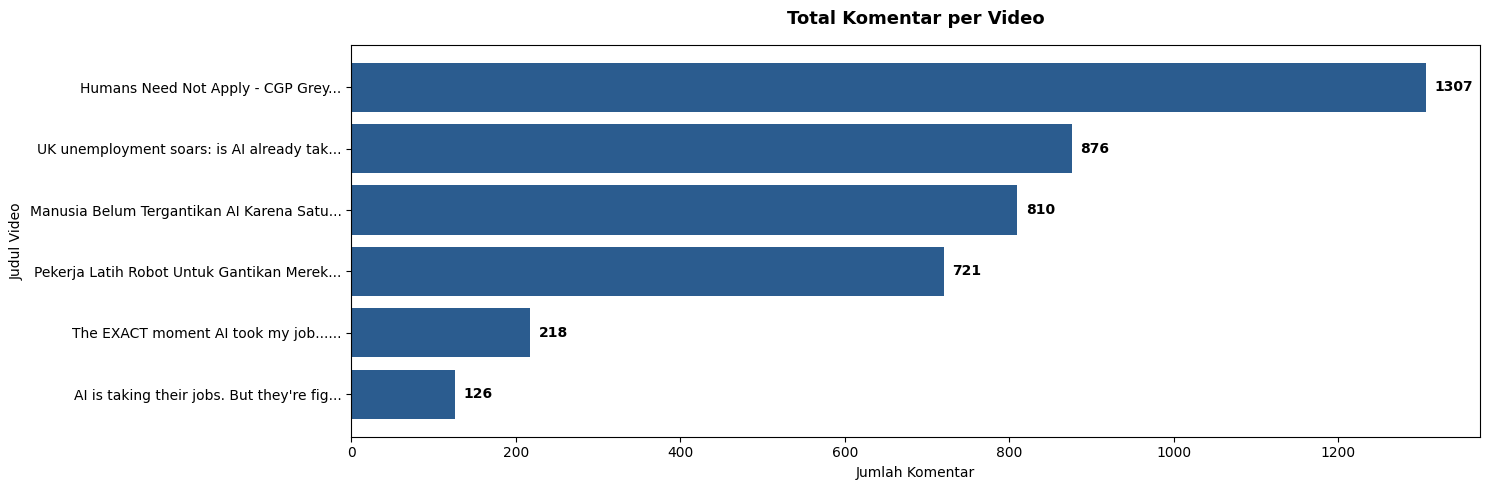

In [161]:
import matplotlib.pyplot as plt

# 1. Hitung total komentar per video
video_counts = df['video_title'].value_counts()

# 2. Potong judul video agar grafik tidak terlalu berantakan/panjang
judul_singkat = [j[:40] + '...' for j in video_counts.index]

# 3. Plot Bar Chart Horizontal
plt.figure(figsize=(15, 5))
bars = plt.barh(judul_singkat, video_counts.values, color='#2b5c8f')

# 4. Tambahkan angka jumlah komentar di ujung setiap bar
for bar in bars:
    width = bar.get_width()
    plt.text(width + 10, bar.get_y() + bar.get_height()/2, f'{int(width)}',
             va='center', fontweight='bold')

plt.title('Total Komentar per Video', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Jumlah Komentar')
plt.ylabel('Judul Video')
plt.gca().invert_yaxis()  # Urutkan dari yang terbanyak di atas
plt.tight_layout()
plt.show()